# ELECTRONIC SUPPLEMENTARY MATERIAL 2
# Machine learning workflow for multivariate classification of igneous suites

**Article:** *Beyond bivariate plots: A machine learning workflow for multivariate classification of igneous suites in the northeastern Borborema Province, Brazil*
**Journal:** Earth Science Informatics
**Authors:** Botello, G. E.\*, Hollanda, M. H. B. M., Carneiro, C. C., Marques, G. R., and Lucas, D.

\* Corresponding author
Affiliation: Instituto de Geociências, Universidade de São Paulo, SP, Brazil
E-mail: botello@usp.br

This notebook consolidates the full pipeline of this article as follows:

1. Libraries and folder configuration
2. Dataset pre-processing
   1. Data cleaning
   2. Data imputation
   3. Data construction
   4. Data transformation
   5. Data Consolidation
3. Exploratory variable assessment and final dataset for machine learning
4. Machine learning analysis
   1. Supervised analysis (Random Forest and LightGBM)
   2. Unsupervised analysis (SOM + K-means)
      - Contingency table (pre-defined magmatic suites vs. unsupervised clusters)
      - Template neurons by pre-defined magmatic suite
6. PCA: pre-defined magmatic suites vs. unsupervised clusters
7. Geochemical figures (Figures 2 and 3)

## 1. Libraries and folder configuration

In [3]:
# Basic libraries
import os
import json
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import RegularPolygon, Polygon
import seaborn as sns
import joblib

# CIPW Norm
import pyrolite
from pyrolite.mineral.normative import CIPW_norm

# Machine learning
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,roc_auc_score, f1_score)
from sklearn.ensemble import RandomForestClassifier
import lightgbm
from lightgbm import LGBMClassifier
import imblearn
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTETomek
from imblearn.pipeline import Pipeline
from collections import Counter
import intrasom
from intrasom import SOMFactory
from intrasom.visualization import PlotFactory
from intrasom.clustering import ClusterFactory

plt.rcParams["pdf.fonttype"] = 42
warnings.filterwarnings("ignore")

print("Versions")
print("numpy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", sns.__version__)
print("pyrolite:", pyrolite.__version__)
print("scikit-learn:", sklearn.__version__)
print("LightGBM:", lightgbm.__version__)
print("Imbalanced-learn:", imblearn.__version__)
from importlib.metadata import version
print("intrasom:", version("intrasom"))

Versions
numpy: 2.4.6
pandas: 3.0.5
matplotlib: 3.8.4
seaborn: 0.13.2
pyrolite: 0.3.6
scikit-learn: 1.9.0
LightGBM: 4.6.0
Imbalanced-learn: 0.14.2
intrasom: 1.1.2


In [4]:
# Folder configuration
# Edit ROOT_DIR to point to the folder that contains the dataset subfolder.

ROOT_DIR = Path(".")

# Fixed random seed, used throughout the notebook (SOM training in Section 2.2/4.2, and the classifiers in Section 4.1) for reproducibility.
RANDOM_STATE = 42

PATHS = {
    "raw_data":     ROOT_DIR / "Dataset" / "Granites-DRN-Geochemistry.xlsx",
    "results_dir":  ROOT_DIR / "Results",  
    "figures_dir":  ROOT_DIR / "Figures", 
}

for key, p in PATHS.items():
    if key.endswith("_dir"):
        p.mkdir(parents=True, exist_ok=True)

## 2. Dataset pre-processing

In [6]:
# Dataset 
df_raw = pd.read_excel(PATHS["raw_data"])
print("Raw data shape:", df_raw.shape)
df_raw.head()

Raw data shape: (771, 70)


,Longitude,Latitude,Sample Location,Sample,Label,Pluton,Reference,Nascimento et al 2015,Major elements,Trace and REE,...,Sm,Eu,Gd,Tb,Dy,Ho,Er,Tm,Yb,Lu
0,-35.984,-6.074,Estimated,RC-7A,Shos,Barcelona,Dados cedidos por A.C. Galindo,YES,XRF,NOT DATA,...,2.37,1.00,2.44,NaN,1.99,NaN,0.634,NaN,0.546,0.058
1,-37.851,-6.414,Estimated,VC-640,Shos,Catolé do Rocha,Medeiros. V.C.; Galindo. A.C.; Nascimento. M.A...,YES,ICP-OES,ICP-MS,...,14.30,4.00,10.41,1.55,8.07,1.43,3.900,0.58,3.360,0.500
2,-36.638,-6.402,Estimated,ED107A,Shos,Acari,Jardim de Sá. E.F. (1994). A Faixa Seridó (Pro...,YES,ICP-OES,ICP-MS,...,9.53,2.39,7.74,NaN,4.95,NaN,2.500,NaN,1.890,0.300
3,-36.558,-6.187,Estimated,ED113,Shos,Totoró,Jardim de Sá. E.F. (1994). A Faixa Seridó (Pro...,YES,ICP-OES,ICP-MS,...,11.76,3.06,9.85,NaN,7.26,NaN,3.580,NaN,2.910,0.400
4,-37.185,-6.793,Estimated,ED59,Shos,SJSabugi,Jardim de Sá. E.F. (1994). A Faixa Seridó (Pro...,YES,ICP-OES,ICP-MS,...,4.14,1.26,3.29,NaN,2.54,NaN,1.300,NaN,1.080,0.160


### 2.1. Data cleaning

Variables with more than 50% missing values within each suite label were excluded from the dataset.

In [8]:
# Missing-value fraction computed separately within each magmatic suite (Label), then the worst case across suites is used to decide whether a variable is kept.

missing_by_label = df_raw.groupby("Label").apply(lambda g: g.isnull().mean())
max_missing_within_label = missing_by_label.max(axis=0)

keep_cols = max_missing_within_label[max_missing_within_label <= 0.50].index
# groupby("Label").apply(...) drops the grouping column itself from the result, so it has to be added back explicitly here.
keep_cols = keep_cols.union(["Label"])
dropped_cols = max_missing_within_label[max_missing_within_label > 0.50].index.tolist()

print(f"Dropped {len(dropped_cols)} columns (>50% missing values within at least one magmatic suite):")
print(dropped_cols)

print(f"Kept {len(keep_cols)} columns (<50% missing values within at least one magmatic suite):")
print(list(keep_cols))

max_missing_within_label[keep_cols.drop("Label")].sort_values()

Dropped 42 columns (>50% missing values within at least one magmatic suite):
['H2O', 'Cr', 'Ni', 'Co', 'Sc', 'V', 'Cu', 'Pb', 'Zn', 'Ti', 'Sn', 'W', 'Mo', 'As', 'Cs', 'Ga', 'Ta', 'Hf', 'Th', 'U', 'Be', 'Ag', 'Au', 'Bi', 'Cd', 'Hg', 'Sb', 'Se', 'La', 'Ce', 'Pr', 'Nd', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Er', 'Tm', 'Yb', 'Lu']
Kept 28 columns (<50% missing values within at least one magmatic suite):
['Al2O3', 'Ba', 'CaO', 'Fe2O3', 'K2O', 'LOI', 'Label', 'Latitude', 'Longitude', 'Major elements', 'MgO', 'MnO', 'Na2O', 'Nascimento et al 2015', 'Nb', 'P2O5', 'Pluton', 'Rb', 'Reference', 'Sample', 'Sample Location', 'SiO2', 'Sr', 'TiO2', 'Total', 'Trace and REE', 'Y', 'Zr']


Al2O3                    0.000000
CaO                      0.000000
Fe2O3                    0.000000
K2O                      0.000000
Longitude                0.000000
Latitude                 0.000000
Na2O                     0.000000
Major elements           0.000000
Pluton                   0.000000
Nascimento et al 2015    0.000000
Trace and REE            0.000000
Total                    0.000000
SiO2                     0.000000
Sample Location          0.000000
Sample                   0.000000
Reference                0.000000
TiO2                     0.025641
P2O5                     0.062271
MnO                      0.083333
Rb                       0.168498
Sr                       0.172161
Y                        0.207865
Zr                       0.214286
Nb                       0.263736
MgO                      0.285714
LOI                      0.428571
Ba                       0.428571
dtype: float64

In [9]:
# Dataset after cleaning
df_filtered = df_raw[keep_cols]

In [10]:
# Master reference lists (standard whole-rock geochemistry nomenclature).
MASTER_OXIDES = [
    "SiO2", "TiO2", "Al2O3", "Fe2O3", "FeO", "MnO", "MgO", "CaO",
    "Na2O", "K2O", "P2O5", "Cr2O3", "NiO",
]
MASTER_TRACE_ELEMENTS = [
    "Rb", "Ba", "Sr", "Nb", "Zr", "Y", "Th", "U", "Ta", "Hf", "Pb", "Ga",
    "Sc", "V", "Cr", "Co", "Ni", "Cu", "Zn", "Cs", "Sn", "W", "Mo", "As",
    "Cd", "Sb", "Bi", "Se", "Be", "Ag", "Au", "Hg",
    "La", "Ce", "Pr", "Nd", "Sm", "Eu", "Gd", "Tb", "Dy", "Ho", "Er", "Tm", "Yb", "Lu",
]

# Only keep whichever of these actually survived the >50%-missing-per-suite
OXIDES = [c for c in MASTER_OXIDES if c in df_filtered.columns]
TRACE_ELEMENTS = [c for c in MASTER_TRACE_ELEMENTS if c in df_filtered.columns]

print("OXIDES present after cleaning:", OXIDES)
print("TRACE_ELEMENTS present after cleaning:", TRACE_ELEMENTS)

OXIDES present after cleaning: ['SiO2', 'TiO2', 'Al2O3', 'Fe2O3', 'MnO', 'MgO', 'CaO', 'Na2O', 'K2O', 'P2O5']
TRACE_ELEMENTS present after cleaning: ['Rb', 'Ba', 'Sr', 'Nb', 'Zr', 'Y']


### 2.2. Data imputation

Two types of missing data are handled here in this order. Values reported below the detection limit ("<value" strings) are first replaced with a fixed value equal to half the typical detection limit for that variable's type (0.005 for oxides and 0.05 for trace elements). This is a deterministic, per-variable rule, not a statistical estimate. Then, values that are absent (NaN) are imputed using IntraSOM's native missing-data handling (missing=True).

In [12]:
# values below detection limit ("<value" strings)

below_dl_cols = df_filtered.columns[
    df_filtered.apply(lambda col: col.astype(str).str.strip().str.startswith("<").any())
]
print("Columns with below-detection-limit values:", list(below_dl_cols))

DL_VALUES = {}
for col in below_dl_cols:
    if col in OXIDES:
        DL_VALUES[col] = 0.005
    elif col in TRACE_ELEMENTS:
        DL_VALUES[col] = 0.05
    else:
        raise ValueError(
            f"Column '{col}' has below-detection-limit values but is not in "
            "OXIDES or TRACE_ELEMENTS; add it to the appropriate master list."
        )
print("Replacement values:", DL_VALUES)

Columns with below-detection-limit values: ['MgO', 'P2O5']
Replacement values: {'MgO': 0.005, 'P2O5': 0.005}


In [13]:
# Apply the replacement

def replace_below_detection_limit(df, dl_values):
    """Replace values below detection limit (strings starting with '<') with
    a fixed value per column, given in `dl_values` (dict: column -> value),
    then coerce numeric-looking strings to float.
    """
    def _replace(x, col):
        if isinstance(x, str) and x.strip().startswith("<"):
            return dl_values.get(col, np.nan)
        return x

    df_clean = df.apply(lambda col: col.map(lambda x: _replace(x, col.name)))
    df_clean = df_clean.map(
        lambda x: float(x) if isinstance(x, str) and x.replace(".", "", 1).isdigit() else x
    )
    return df_clean


df_clean = replace_below_detection_limit(df_filtered, DL_VALUES)

In [14]:
# # Check the remaining missing values per variable

IMPUTATION_VARIABLES = OXIDES + TRACE_ELEMENTS

print("Missing values per variable:")
print(df_clean[IMPUTATION_VARIABLES].isna().sum())
print("\nTotal missing values:", df_clean[IMPUTATION_VARIABLES].isna().sum().sum())

Missing values per variable:
SiO2       0
TiO2       7
Al2O3      0
Fe2O3      0
MnO       15
MgO        8
CaO        0
Na2O       0
K2O        0
P2O5      19
Rb        92
Ba       146
Sr        95
Nb       151
Zr       127
Y        127
dtype: int64

Total missing values: 787


In [15]:
# Impute the missing values with IntraSOM and check that none remain

SOM_MAPSIZE = (20, 20)


def build_som(data, mapsize=SOM_MAPSIZE, missing=True, name="granitoids", random_state=RANDOM_STATE):
    """Build and train a SOM with reproducible results.

    IntraSOM's `SOMFactory.build` has no seed parameter of its own - its
    "random" initialization (required here since the data still has missing
    values) and, per its own documentation, the random regularization factor
    used internally during missing-data training both draw from NumPy's
    global random state. Seeding it here makes repeated runs of this
    function reproducible. `n_job=1` (no parallelism) is used for the same
    reason: with `n_job=-1`, each parallel worker may not share the seeded
    state of the main process, which would silently reintroduce
    non-reproducibility.
    """
    np.random.seed(random_state)
    som = intrasom.SOMFactory.build(
        data=data,
        mapsize=mapsize,
        mapshape="toroid",
        lattice="hexa",
        normalization="var",
        initialization="random",
        neighborhood="gaussian",
        training="batch",
        name=name,
        missing=missing,
    )
    som.train(
        n_job=1,
        shared_memory=True,
        save=True,
        summary=True,
        dtypes="parquet",
    )
    return som


values_for_imputation = df_clean[IMPUTATION_VARIABLES]

som_imputation = build_som(values_for_imputation, mapsize=SOM_MAPSIZE, missing=True, name="granitoids_imputation")

imputed_values = som_imputation.imput_missing()

df_imputed = df_clean.copy()
df_imputed[IMPUTATION_VARIABLES] = imputed_values[IMPUTATION_VARIABLES].values

n_missing_after = df_imputed[IMPUTATION_VARIABLES].isna().sum().sum()
print("Missing values after imputation:", n_missing_after)
assert n_missing_after == 0, "Imputation did not resolve all missing values."

df_imputed.head()

Loading dataframe...
Normalizing data...
Creating neighborhood...
Loading distances matrix...
Initializing map...


Creating Neuron Distance Rows:   0%|          | 0/20 [00:00<?, ?rows/s]

Starting Training...
Rough Training:


  0%|          | 0/16 [00:00<?, ?it/s]

Fine Tuning:


  0%|          | 0/26 [00:00<?, ?it/s]

Saving...
Training Report Created
Training completed successfully.
Missing values after imputation: 0


,Al2O3,Ba,CaO,Fe2O3,K2O,LOI,Label,Latitude,Longitude,Major elements,...,Reference,Sample,Sample Location,SiO2,Sr,TiO2,Total,Trace and REE,Y,Zr
0,15.60,115.0,9.60,13.20,1.80,0.95,Shos,-6.074,-35.984,XRF,...,Dados cedidos por A.C. Galindo,RC-7A,Estimated,46.70,180.0,1.60,100.87,NOT DATA,15.0,23.0
1,14.78,2151.3,6.21,14.89,3.34,0.60,Shos,-6.414,-37.851,ICP-OES,...,Medeiros. V.C.; Galindo. A.C.; Nascimento. M.A...,VC-640,Estimated,47.38,742.9,2.75,99.58,ICP-MS,42.8,338.0
2,15.63,887.0,8.44,14.48,1.39,1.14,Shos,-6.402,-36.638,ICP-OES,...,Jardim de Sá. E.F. (1994). A Faixa Seridó (Pro...,ED107A,Estimated,47.53,684.0,2.20,99.63,ICP-MS,29.0,246.0
3,15.78,868.0,8.83,13.08,1.45,0.74,Shos,-6.187,-36.558,ICP-OES,...,Jardim de Sá. E.F. (1994). A Faixa Seridó (Pro...,ED113,Estimated,48.27,604.0,2.08,99.65,ICP-MS,43.0,271.0
4,16.21,562.0,8.89,14.64,1.21,0.87,Shos,-6.793,-37.185,ICP-OES,...,Jardim de Sá. E.F. (1994). A Faixa Seridó (Pro...,ED59,Estimated,48.32,930.0,1.64,99.65,ICP-MS,15.0,89.0


In [16]:
# measures to observe how the data change by magmatic suite before and after the imputation of NaNs

def stats_by_label(df, variables, label_col="Label"):
    """mean/std per Label, for the given variables."""
    return df.groupby(label_col)[variables].agg(["mean", "std"])


stats_before_label = stats_by_label(df_clean, IMPUTATION_VARIABLES)
stats_after_label = stats_by_label(df_imputed, IMPUTATION_VARIABLES)


In [17]:
# Percentage change in the mean, per suite and per variable

mean_change_by_label = (
    (stats_after_label.xs("mean", axis=1, level=1) - stats_before_label.xs("mean", axis=1, level=1))
    / stats_before_label.xs("mean", axis=1, level=1) * 100
).round(2)

mean_change_by_label

,SiO2,TiO2,Al2O3,Fe2O3,MnO,MgO,CaO,Na2O,K2O,P2O5,Rb,Ba,Sr,Nb,Zr,Y
Label,,,,,,,,,,,,,,,,
Alk,0.0,-0.0,0.0,-0.0,-1.36,0.59,-0.0,-0.0,-0.0,-0.63,0.48,-4.84,-0.81,0.33,-2.58,-0.99
Calk,0.0,0.0,0.0,0.0,0.00,0.00,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.42,0.00,0.00
ChAlk,0.0,0.0,0.0,0.0,0.00,27.33,0.0,0.0,0.0,0.00,-0.17,8.45,4.82,0.30,0.60,-0.26
EqHKCalk,0.0,-0.2,0.0,0.0,-0.18,-0.20,0.0,0.0,0.0,0.27,-2.05,5.93,13.23,-4.49,-0.70,-5.50
PHKCalk,0.0,0.0,0.0,0.0,-0.18,0.00,0.0,0.0,0.0,0.05,-3.72,2.89,8.21,-6.02,-5.33,-9.88
Shos,0.0,0.0,0.0,0.0,-0.08,-0.00,0.0,-0.0,-0.0,-0.00,1.46,0.69,0.77,-2.83,0.11,-2.61


In [18]:
# Percentage change in the std per suite and per variable

std_before_label = stats_before_label.xs("std", axis=1, level=1)
std_after_label = stats_after_label.xs("std", axis=1, level=1)

std_change_by_label = ((std_after_label - std_before_label) / std_before_label * 100).round(2)
std_change_by_label

,SiO2,TiO2,Al2O3,Fe2O3,MnO,MgO,CaO,Na2O,K2O,P2O5,Rb,Ba,Sr,Nb,Zr,Y
Label,,,,,,,,,,,,,,,,
Alk,0.0,-0.00,0.0,0.0,-3.98,-1.23,0.0,-0.0,-0.0,-0.60,-1.01,12.78,0.19,-3.15,-7.42,-2.99
Calk,0.0,0.00,0.0,0.0,0.00,0.00,0.0,0.0,0.0,0.00,0.00,0.00,0.00,-14.11,0.00,0.00
ChAlk,0.0,0.00,0.0,0.0,0.00,14.42,0.0,0.0,0.0,0.00,-3.83,57.79,18.36,-3.75,-3.49,-3.88
EqHKCalk,0.0,-1.07,0.0,0.0,-0.67,-0.31,0.0,0.0,0.0,-2.36,1.81,5.68,10.95,-12.66,-4.20,-4.97
PHKCalk,0.0,0.00,0.0,0.0,-0.24,0.00,0.0,0.0,0.0,-0.25,-2.41,0.11,5.92,-8.38,-0.76,-4.52
Shos,-0.0,0.00,0.0,0.0,-0.85,0.00,-0.0,-0.0,-0.0,-0.00,-2.95,-2.57,-3.78,-4.93,-3.28,-6.31


In [19]:
# Total oxide sum per sample, and its range per suite 

#This is purely to confirm that the imputation makes sense. After imputing the missing oxide values, 
#the total should still be within the expected range for whole-rock analyses (close to 100%).

oxide_total = df_imputed[OXIDES].sum(axis=1)
oxide_total_by_label = oxide_total.groupby(df_imputed["Label"]).agg(["min", "max", "mean", "std"])
oxide_total_by_label["range"] = oxide_total_by_label["max"] - oxide_total_by_label["min"]

print(oxide_total_by_label.round(2))

            min     max   mean   std  range
Label                                      
Alk       98.20  101.34  99.37  0.51   3.14
Calk      97.66  101.83  99.20  0.88   4.17
ChAlk     97.94  101.03  99.52  1.04   3.09
EqHKCalk  97.19  101.88  99.36  0.75   4.69
PHKCalk   97.78  102.69  99.37  0.86   4.91
Shos      97.03  101.21  98.95  0.64   4.18


### 2.3. Data construction

Standard petrological indices are computed from the imputed major oxides, and CIPW normative mineralogy is obtained with `pyrolite.mineral.normative.CIPW_norm`. Both are computed on the imputed dataset.

> **Note on LOI:** no LOI correction is applied in this workflow since LOI is not available for all samples. Correcting only some samples would result in a mixture of corrected and uncorrected compositions in the same modeling space.

In [21]:
def compute_geochemical_indices(df):
    """Compute geochemical indices from the imputed dataset"""
    df = df.copy()
    df["NKC"] = df["Na2O"] + df["K2O"] - df["CaO"]

    df["A/NK"] = (df["Al2O3"] / 101.96) / (
        (df["Na2O"] / 61.98) + (df["K2O"] / 94.20)
    )
    df["A/CNK"] = (df["Al2O3"] / 101.96) / (
        (df["CaO"] / 56.08) + (df["Na2O"] / 61.98) + (df["K2O"] / 94.20)
    )

    df["FeOT"] = df["Fe2O3"] * 0.89981
    df["M/MF"] = (df["MgO"] / 40.3 * 1000) / (
        (df["FeOT"] / 71.8 * 1000) + (df["MgO"] / 40.3 * 1000)
    )
    df["FMT"] = (
        (df["FeOT"] / 71.8 * 1000) + (df["MgO"] / 40.3 * 1000) + (df["TiO2"] / 79.8 * 1000)
    )
    df["K/NK"] = (df["K2O"] / 94.20 * 2 * 1000) / (
        (df["Na2O"] / 61.98 * 2 * 1000) + (df["K2O"] / 94.20 * 2 * 1000)
    )
    return df


GEOCHEM_INDICES = ["NKC", "A/NK", "A/CNK", "M/MF", "FMT", "K/NK"]


def compute_cipw_norm(df, oxides=OXIDES, save_path=None):
    """ FeO is not analyzed separately in this dataset, so it is set to NaN and total Fe is apportioned between Fe2O3/FeO internally 
    by `CIPW_norm`(LeMaitre plutonic Fe-correction scheme)"""
    df_cipw = df[oxides].copy()
    df_cipw["FeO"] = np.nan

    norms = CIPW_norm(
        df=df_cipw,
        Fe_correction="LeMaitre",
        Fe_correction_mode="plutonic",
        adjust_all_Fe=True,
        rounding=3)

    # Drop mineral columns with no data at all across the dataset
    norms = norms.loc[:, norms.columns[norms.any()]]

    # Redundant minerals not needed downstream (diopside/hypersthene/olivine are fully described by their end-members already retained)
    norms = norms.drop(columns=["diopside", "hypersthene", "olivine"], errors="ignore")

    if save_path is not None:
        norms.to_excel(save_path)
    return norms

In [22]:
# Calculate: Geochemical indices + CIPW norm (on the complete dataset, df_imputed)

norms_filt = compute_cipw_norm(df_imputed, save_path=PATHS["results_dir"] / "Results_NormCIPW.xlsx")
df_construction = compute_geochemical_indices(df_imputed)
df_construction = pd.concat([df_construction, norms_filt], axis=1)
df_construction.head()

,Al2O3,Ba,CaO,Fe2O3,K2O,LOI,Label,Latitude,Longitude,Major elements,...,corundum,magnetite,hematite,forsterite,fayalite,clinoferrosilite,clinoenstatite,ferrosilite,enstatite,wollastonite
0,15.60,115.0,9.60,13.20,1.80,0.95,Shos,-6.074,-35.984,XRF,...,0.0,5.980,0.0,9.158,4.954,5.818,13.595,0.000,0.000,0.0
1,14.78,2151.3,6.21,14.89,3.34,0.60,Shos,-6.414,-37.851,ICP-OES,...,0.0,7.586,0.0,2.643,1.895,0.955,1.684,4.860,7.469,0.0
2,15.63,887.0,8.44,14.48,1.39,1.14,Shos,-6.402,-36.638,ICP-OES,...,0.0,6.517,0.0,3.849,3.423,5.425,7.710,2.623,3.249,0.0
3,15.78,868.0,8.83,13.08,1.45,0.74,Shos,-6.187,-36.558,ICP-OES,...,0.0,5.969,0.0,5.006,3.596,5.299,9.325,1.190,1.825,0.0
4,16.21,562.0,8.89,14.64,1.21,0.87,Shos,-6.793,-37.185,ICP-OES,...,0.0,6.334,0.0,1.342,1.488,6.269,7.143,6.078,6.038,0.0


In [23]:
print(df_construction.columns)

Index(['Al2O3', 'Ba', 'CaO', 'Fe2O3', 'K2O', 'LOI', 'Label', 'Latitude',
       'Longitude', 'Major elements', 'MgO', 'MnO', 'Na2O',
       'Nascimento et al 2015', 'Nb', 'P2O5', 'Pluton', 'Rb', 'Reference',
       'Sample', 'Sample Location', 'SiO2', 'Sr', 'TiO2', 'Total',
       'Trace and REE', 'Y', 'Zr', 'NKC', 'A/NK', 'A/CNK', 'FeOT', 'M/MF',
       'FMT', 'K/NK', 'quartz', 'anorthite', 'albite', 'orthoclase',
       'nepheline', 'apatite', 'ilmenite', 'corundum', 'magnetite', 'hematite',
       'forsterite', 'fayalite', 'clinoferrosilite', 'clinoenstatite',
       'ferrosilite', 'enstatite', 'wollastonite'],
      dtype='str')


### 2.4. Data transformation

Several of the algorithms used in this workflow — including Principal Component Analysis (PCA), SMOTETomek, Self-Organizing Map (SOM), and K-means  — 
rely on Euclidean distances or variance-based calculations, and therefore require variables to be on comparable, standardized scales. 

For this reason, four transformations are applied here, one per variable block:

| Variable block | Transformation |
|---|---|
| Major oxides | Centered log-ratio (CLR) |
| CIPW normative minerals | Centered log-ratio (CLR) |
| Trace elements | z-score |
| Geochemical indices | z-score |

The centered log-ratio transformation was then applied to major oxides and normative minerals, which represent closed compositional systems. This transformation projects compositional data into real Euclidean space and reduces purious correlations resulting from the constant-sum constraint. 

Trace elements and geochemical indices were standardized using z-score scaling to ensure comparability among variables with different magnitudes and units.

In [25]:
def clr_transform(df, columns, suffix="-CLR"):
    """Centered log-ratio (CLR) transformation of strictly positive columns.

    Parameters
    ----------
    df : pd.DataFrame
        Complete (no missing values) input data.
    columns : list of str
        Columns to transform jointly (their row-wise geometric mean defines the closure used by the CLR transform).
    suffix : str
        Suffix appended to the transformed column names.
    """
    values = df[columns].values
    if (values <= 0).any():
        raise ValueError(
            "CLR transformation requires strictly positive values; "
            "replace exact zeros with a small constant before calling this function."
        )
    geometric_means = np.exp(np.mean(np.log(values), axis=1))
    clr_values = np.log(values / geometric_means[:, np.newaxis])
    return pd.DataFrame(clr_values, columns=[f"{c}{suffix}" for c in columns], index=df.index)


def standardize(df, columns, suffix="_sc"):
    """Standardize columns to zero mean / unit variance (StandardScaler)."""
    scaler = StandardScaler()
    scaled = scaler.fit_transform(df[columns])
    return pd.DataFrame(scaled, columns=[f"{c}{suffix}" for c in columns], index=df.index), scaler

In [26]:
# Transformation: CLR (oxides, minerals) + z-score (traces, indices) 

clr_oxides = clr_transform(df_construction, OXIDES)

# CIPW normative minerals can contain exact zeros(a mineral genuinely absent from a sample's norm), which CLR cannot take the log of; 
#these are replaced by a small constant before transforming, following standard compositional-data practice.
mineral_cols = list(norms_filt.columns)
clr_minerals = clr_transform(norms_filt.replace(0, 0.00001), mineral_cols)

scaled_traces, trace_scaler = standardize(df_construction, TRACE_ELEMENTS)
scaled_indices, index_scaler = standardize(df_construction, GEOCHEM_INDICES)

CLR_OXIDES = list(clr_oxides.columns)
CLR_MINERALS = list(clr_minerals.columns)
SCALED_TRACES = list(scaled_traces.columns)
SCALED_INDICES = list(scaled_indices.columns)

print("CLR oxide columns:", CLR_OXIDES)
print("CLR mineral columns:", CLR_MINERALS)
print("Scaled trace columns:", SCALED_TRACES)
print("Scaled index columns:", SCALED_INDICES)

CLR oxide columns: ['SiO2-CLR', 'TiO2-CLR', 'Al2O3-CLR', 'Fe2O3-CLR', 'MnO-CLR', 'MgO-CLR', 'CaO-CLR', 'Na2O-CLR', 'K2O-CLR', 'P2O5-CLR']
CLR mineral columns: ['quartz-CLR', 'anorthite-CLR', 'albite-CLR', 'orthoclase-CLR', 'nepheline-CLR', 'apatite-CLR', 'ilmenite-CLR', 'corundum-CLR', 'magnetite-CLR', 'hematite-CLR', 'forsterite-CLR', 'fayalite-CLR', 'clinoferrosilite-CLR', 'clinoenstatite-CLR', 'ferrosilite-CLR', 'enstatite-CLR', 'wollastonite-CLR']
Scaled trace columns: ['Rb_sc', 'Ba_sc', 'Sr_sc', 'Nb_sc', 'Zr_sc', 'Y_sc']
Scaled index columns: ['NKC_sc', 'A/NK_sc', 'A/CNK_sc', 'M/MF_sc', 'FMT_sc', 'K/NK_sc']


**Saving the fitted scalers.** `trace_scaler` and `index_scaler` (fit above) are saved to disk here so they can be reused in ESM_4.

In [28]:
joblib.dump(trace_scaler, PATHS["results_dir"] / "trace_scaler.joblib")
joblib.dump(index_scaler, PATHS["results_dir"] / "index_scaler.joblib")
print("Saved fitted scalers:")
print("  -", PATHS["results_dir"] / "trace_scaler.joblib")
print("  -", PATHS["results_dir"] / "index_scaler.joblib")

Saved fitted scalers:
  - Results\trace_scaler.joblib
  - Results\index_scaler.joblib


### 2.5. Data Consolidation

All transformed variable blocks (Section 2.4) are concatenated with the
constructed dataset (Section 2.3) into a single, final modeling table
(`df_final`), which every downstream section of this notebook uses.

In [30]:
# Consolidate final modeling dataset

metadata_cols = [c for c in df_construction.columns if c not in OXIDES + TRACE_ELEMENTS + GEOCHEM_INDICES + mineral_cols]

df_final = pd.concat([df_construction, clr_oxides, scaled_traces, scaled_indices, clr_minerals], axis=1)

column_order = (
    metadata_cols
    + OXIDES
    + TRACE_ELEMENTS
    + GEOCHEM_INDICES
    + mineral_cols
    + CLR_OXIDES
    + SCALED_TRACES
    + SCALED_INDICES
    + CLR_MINERALS
)
df_final = df_final[column_order]

df_final.to_excel(PATHS["results_dir"] / "Granites-DRN-Geochemistry-results-preprocessing.xlsx", index=False)

df_final.head()

,LOI,Label,Latitude,Longitude,Major elements,Nascimento et al 2015,Pluton,Reference,Sample,Sample Location,...,corundum-CLR,magnetite-CLR,hematite-CLR,forsterite-CLR,fayalite-CLR,clinoferrosilite-CLR,clinoenstatite-CLR,ferrosilite-CLR,enstatite-CLR,wollastonite-CLR
0,0.95,Shos,-6.074,-35.984,XRF,YES,Barcelona,Dados cedidos por A.C. Galindo,RC-7A,Estimated,...,-8.657124,4.644222,-8.657124,5.070429,4.455996,4.616758,5.465503,-8.657124,-8.657124,-8.657124
1,0.60,Shos,-6.414,-37.851,ICP-OES,YES,Catolé do Rocha,Medeiros. V.C.; Galindo. A.C.; Nascimento. M.A...,VC-640,Estimated,...,-9.295301,4.243928,-9.295301,3.189539,2.856843,2.171580,2.738796,3.798662,4.228385,-9.295301
2,1.14,Shos,-6.402,-36.638,ICP-OES,YES,Acari,Jardim de Sá. E.F. (1994). A Faixa Seridó (Pro...,ED107A,Estimated,...,-9.336355,4.050984,-9.336355,3.524384,3.407088,3.867588,4.219088,3.140889,3.354918,-9.336355
3,0.74,Shos,-6.187,-36.558,ICP-OES,YES,Totoró,Jardim de Sá. E.F. (1994). A Faixa Seridó (Pro...,ED113,Estimated,...,-9.282709,4.016796,-9.282709,3.840854,3.510039,3.897735,4.462916,2.404170,2.831797,-9.282709
4,0.87,Shos,-6.793,-37.185,ICP-OES,YES,SJSabugi,Jardim de Sá. E.F. (1994). A Faixa Seridó (Pro...,ED59,Estimated,...,-9.251928,4.106929,-9.251928,2.555158,2.658430,4.096614,4.227130,4.065673,4.059070,-9.251928


## 3. Exploratory variable assessment and final dataset for machine learning

Separate PCA analyses were conducted for each variable group – major oxides, trace elements, normative minerals, and geochemical indices, to evaluate whether they contributed meaningful discriminatory information for the subsequent machine-learning analyses.

In [32]:
# Functions
# _plot_pca_biplot: draws one PCA biplot (points + loading vectors) onto a given axis, reused by plot_pca_combined and plot_pca_pair (Section 5).
# plot_pca_combined: runs PCA on several variable groups and arranges all biplots into one 2x2 figure with a shared legend.

def _plot_pca_biplot(ax, principal_components, loadings, variables, variance_pct,
                      hue_series, palette, loading_scale=3, panel_label=None):
    """Draw one PCA biplot (PC1 vs PC2, points colored by hue_series, with
    loading vectors) onto a given matplotlib axis.
    """
    for category, color in palette.items():
        mask = (hue_series == category).values
        ax.scatter(
            principal_components[mask, 0], principal_components[mask, 1],
            facecolor=color, edgecolor="white", linewidth=0.4,
            s=28, alpha=0.9, marker="o", label=category, zorder=3,
        )

    for i in range(loadings.shape[1]):
        ax.quiver(0, 0, loadings[0, i] * loading_scale, loadings[1, i] * loading_scale,
                  angles="xy", scale_units="xy", scale=1, color="black", width=0.004, zorder=4)
        ax.text(loadings[0, i] * loading_scale * 1.12, loadings[1, i] * loading_scale * 1.12,
               variables[i], color="black", ha="center", va="center", fontsize=6, zorder=5)

    ax.axhline(0, color="gray", linestyle="--", alpha=0.5, linewidth=0.5)
    ax.axvline(0, color="gray", linestyle="--", alpha=0.5, linewidth=0.5)
    ax.set_xlabel(f"PC1 ({variance_pct[0]:.1f}%)", fontsize=8)
    ax.set_ylabel(f"PC2 ({variance_pct[1]:.1f}%)", fontsize=8)
    ax.set_box_aspect(1)
    ax.tick_params(labelsize=7)

    if panel_label:
        ax.text(-0.12, 1.05, f"({panel_label})", transform=ax.transAxes,
               fontsize=10, fontweight="bold", va="top")



def plot_pca_combined(df, pca_groups, hue_col, palette, loading_scale=3, save_path=None,
                       max_width_mm=174, max_height_mm=185):
    """2x2 combined PCA figure (a: oxides, b: traces, c: indices, d: minerals),
    sized to fit within the journal's maximum figure dimensions.
    """
    mm_to_in = 1 / 25.4
    figsize = (max_width_mm * mm_to_in, max_height_mm * mm_to_in)

    fig, axes = plt.subplots(2, 2, figsize=figsize)
    axes = axes.ravel()
    hue_series = df[hue_col]

    results = {}
    for ax, (group_name, (variables, panel_label)) in zip(axes, pca_groups.items()):
        pca = PCA()
        pcs = pca.fit_transform(df[variables])
        variance_pct = pca.explained_variance_ratio_ * 100
        loadings = pca.components_

        _plot_pca_biplot(
            ax, pcs, loadings, variables, variance_pct, hue_series, palette,
            loading_scale=loading_scale, panel_label=panel_label,
        )
        ax.set_title(group_name.capitalize(), fontsize=9)

        eigen_df = pd.DataFrame({
            "Principal component": [f"PC{i + 1}" for i in range(len(pca.explained_variance_))],
            "Eigenvalue": pca.explained_variance_,
            "Variance (%)": variance_pct,
            "Cumulative variance (%)": np.cumsum(variance_pct),
        })
        loadings_df = pd.DataFrame(
            loadings.T, columns=[f"PC{i + 1}" for i in range(pca.n_components_)], index=variables,
        )
        results[group_name] = {"eigen": eigen_df, "loadings": loadings_df}

        print(f"\n=== PCA: {group_name} ===")
        print(eigen_df.to_string(index=False))
        print("\nLoadings (PC1, PC2):")
        print(loadings_df[["PC1", "PC2"]].round(3))

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=len(palette),
              fontsize=7, frameon=False, bbox_to_anchor=(0.5, -0.02))

    fig.tight_layout(rect=[0, 0.04, 1, 1])
    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    return results

In [33]:
SUITE_COLORS = {
    "Shos":     "#8F559E",
    "PHKCalk":  "#0059FE",
    "EqHKCalk": "#99D2E7",
    "Calk":     "#FF6600",
    "Alk":      "#EC727E",
    "ChAlk":    "#B90000",
}
suites = np.unique(df_final["Label"])
suite_palette = {s: SUITE_COLORS.get(s, "gray") for s in suites}

pca_groups = {
    "oxides":   (CLR_OXIDES, "a"),
    "traces":   (SCALED_TRACES, "b"),
    "indices":  (SCALED_INDICES, "c"),
    "minerals": (CLR_MINERALS, "d"),
}

pca_results = plot_pca_combined(
    df_final, pca_groups, hue_col="Label", palette=suite_palette,
    save_path=PATHS["figures_dir"] / "PCA_combined_4panel.pdf")


=== PCA: oxides ===
Principal component   Eigenvalue  Variance (%)  Cumulative variance (%)
                PC1 2.280491e+00  7.052301e+01                70.523008
                PC2 3.501905e-01  1.082946e+01                81.352467
                PC3 2.519865e-01  7.792553e+00                89.145020
                PC4 1.494688e-01  4.622246e+00                93.767266
                PC5 1.061592e-01  3.282920e+00                97.050186
                PC6 4.747669e-02  1.468192e+00                98.518378
                PC7 3.403858e-02  1.052625e+00                99.571003
                PC8 1.079921e-02  3.339600e-01                99.904963
                PC9 3.073194e-03  9.503694e-02               100.000000
               PC10 1.934867e-15  5.983475e-14               100.000000

Loadings (PC1, PC2):
             PC1    PC2
SiO2-CLR  -0.378  0.148
TiO2-CLR   0.309 -0.154
Al2O3-CLR -0.280  0.115
Fe2O3-CLR  0.146 -0.123
MnO-CLR    0.026 -0.551
MgO-CLR    0.512  0.6

<Figure size 685.039x728.346 with 4 Axes>

**Note:** normative minerals are included as a PCA variable group in this
chapter, but they are **not** carried into
Chapter 4 (supervised or unsupervised classification); see the article.

## 4. Machine learning analysis
Supervised and unsupervised analysis uses only three variable groups: major oxides, trace
elements, and geochemical indices.

In [36]:
VARIABLES_ML = CLR_OXIDES + SCALED_TRACES + SCALED_INDICES

print("Variables used in Chapter 4 (oxides + traces + geochemical indices):")
print(VARIABLES_ML)

Variables used in Chapter 4 (oxides + traces + geochemical indices):
['SiO2-CLR', 'TiO2-CLR', 'Al2O3-CLR', 'Fe2O3-CLR', 'MnO-CLR', 'MgO-CLR', 'CaO-CLR', 'Na2O-CLR', 'K2O-CLR', 'P2O5-CLR', 'Rb_sc', 'Ba_sc', 'Sr_sc', 'Nb_sc', 'Zr_sc', 'Y_sc', 'NKC_sc', 'A/NK_sc', 'A/CNK_sc', 'M/MF_sc', 'FMT_sc', 'K/NK_sc']


### 4.1. Supervised analysis (Random Forest and LightGBM)

Variables: `VARIABLES_ML` (CLR_OXIDES + SCALED_TRACES + SCALED_INDICES). A `StandardScaler` is applied again **inside** the pipeline, refit on training-fold data only (mathematically equivalent to scaling the raw variables with training-fold statistics directly, so no data leakage occurs regardless of the prior global scaling). 

#### 4.1.a. Hyperparameter selection (sensitivity analysis)

One-at-a-time sensitivity analysis: each hyperparameter is varied in isolation, holding the others at reasonable defaults, evaluating 3-fold cross-validation F1 (weighted) on the training split. No final values are assigned yet - the results below inform the choices made in 4.1.b.

In [39]:
# RANDOM_STATE is already defined in Section 1.

def dynamic_sampling_strategy(y, target_frac=0.4):
    """Oversample minority classes up to `target_frac` of the majority class size."""
    counter = Counter(y)
    max_class_size = max(counter.values())
    threshold = target_frac * max_class_size
    return {label: int(threshold) for label, count in counter.items() if count < threshold}


def sensitivity_analysis(X, y, model_class, fixed_params, param_name, param_values,
                          k_neighbors, random_state=RANDOM_STATE, n_splits=3):
    """One-at-a-time sensitivity analysis: refit the full pipeline (scale +
    SMOTETomek + model) for each value of `param_name`, holding all other
    hyperparameters fixed, and report cross-validation F1 weighted.
    `k_neighbors` is only varied when param_name == "smote_k_neighbors".
    """
    y_encoded = LabelEncoder().fit_transform(y) if pd.Series(y).dtype == "object" else y
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    results = []

    for value in param_values:
        k = value if param_name == "smote_k_neighbors" else k_neighbors
        params = fixed_params if param_name == "smote_k_neighbors" else {**fixed_params, param_name: value}
        model = model_class(**params)

        pipeline = Pipeline([
            ("scale", StandardScaler()),
            ("resample", SMOTETomek(
                smote=SMOTE(k_neighbors=k, random_state=random_state),
                sampling_strategy=dynamic_sampling_strategy,
                random_state=random_state,
            )),
            ("model", model),
        ])

        cv_results = cross_validate(pipeline, X, y_encoded, cv=cv, scoring="f1_weighted")
        results.append({
            param_name if param_name != "smote_k_neighbors" else "k_neighbors": value,
            "f1_weighted_mean": cv_results["test_score"].mean(),
            "f1_weighted_std": cv_results["test_score"].std(),
        })

    return pd.DataFrame(results)

In [40]:
X = df_final[VARIABLES_ML]
y = df_final["Label"]
n_classes = df_final["Label"].nunique()

# --- SMOTE k_neighbors (Random Forest as the reference model) ---
rf_base_params = dict(random_state=RANDOM_STATE, n_estimators=100, criterion="gini",
                       min_samples_leaf=2, max_depth=10, n_jobs=-1)
k_sensitivity = sensitivity_analysis(
    X, y, RandomForestClassifier, rf_base_params,
    param_name="smote_k_neighbors", param_values=[1, 2, 3, 4, 5], k_neighbors=None,
)
print("--- SMOTE k_neighbors sensitivity ---")
print(k_sensitivity.round(4))

# --- Random Forest: min_samples_leaf ---
rf_leaf_sensitivity = sensitivity_analysis(
    X, y, RandomForestClassifier, {**rf_base_params, "max_depth": 10},
    param_name="min_samples_leaf", param_values=[1, 2, 3, 5, 8, 10], k_neighbors=3,
)
print("\n--- min_samples_leaf sensitivity (Random Forest) ---")
print(rf_leaf_sensitivity.round(4))

# --- Random Forest: max_depth ---
rf_depth_sensitivity = sensitivity_analysis(
    X, y, RandomForestClassifier, {**rf_base_params, "min_samples_leaf": 2},
    param_name="max_depth", param_values=[3, 5, 10, 15, 20, None], k_neighbors=3,
)
print("\n--- max_depth sensitivity (Random Forest) ---")
print(rf_depth_sensitivity.round(4))

# --- LightGBM: min_child_samples ---
lgbm_base_params = dict(random_state=RANDOM_STATE, n_estimators=100, learning_rate=0.1,
                         objective="multiclass", num_class=n_classes, subsample=1, colsample_bytree=1,
                         verbosity=-1,  deterministic=True, force_row_wise=True)
lgbm_child_sensitivity = sensitivity_analysis(
    X, y, LGBMClassifier, {**lgbm_base_params, "max_depth": 10},
    param_name="min_child_samples", param_values=[1, 2, 3, 5, 8, 10], k_neighbors=3,
)
print("\n--- min_child_samples sensitivity (LightGBM) ---")
print(lgbm_child_sensitivity.round(4))

# --- LightGBM: max_depth ---
lgbm_depth_sensitivity = sensitivity_analysis(
    X, y, LGBMClassifier, {**lgbm_base_params, "min_child_samples": 2},
    param_name="max_depth", param_values=[3, 5, 10, 15, 20, -1], k_neighbors=3,
)
print("\n--- max_depth sensitivity (LightGBM) ---")
print(lgbm_depth_sensitivity.round(4))

--- SMOTE k_neighbors sensitivity ---
   k_neighbors  f1_weighted_mean  f1_weighted_std
0            1            0.8286           0.0047
1            2            0.8225           0.0034
2            3            0.8186           0.0082
3            4            0.8262           0.0054
4            5            0.8238           0.0134

--- min_samples_leaf sensitivity (Random Forest) ---
   min_samples_leaf  f1_weighted_mean  f1_weighted_std
0                 1            0.8319           0.0094
1                 2            0.8186           0.0082
2                 3            0.8155           0.0049
3                 5            0.8117           0.0153
4                 8            0.8014           0.0180
5                10            0.7962           0.0216

--- max_depth sensitivity (Random Forest) ---
   max_depth  f1_weighted_mean  f1_weighted_std
0        3.0            0.7423           0.0406
1        5.0            0.7826           0.0330
2       10.0            0.8186  

#### 4.1.b. Final models

Hyperparameter values selected from the sensitivity analysis (4.1.a): 

- `SMOTE_K_NEIGHBORS = 4` — F1 scores were statistically indistinguishable across k = 1–5 (0.8186–0.8286), with k = 1 giving the marginally highest score. However, k = 4 was retained rather than k = 1, providing a balance between the two extremes of the viable range. At k = 1, each synthetic sample is generated using a single nearest neighbor, making the procedure more sensitive to local noise and potentially reproducing unusual characteristics of individual samples. At larger values, such as the default k = 5, the available neighbor pool becomes increasingly limited for the smallest suite, Ch-Alk, which has only 6–7 samples in some training folds. This can result in synthetic samples being generated from a very small and highly local subset of the class, providing limited additional diversity. Thus, k = 4 provides a balance between sensitivity to individual observations and the limited number of minority-class samples, at a negligible cost to F1 (0.8262 vs. 0.8286 for k = 1), while being the second-best-performing value overall.

- `min_samples_leaf = 2` (RF) / `min_child_samples = 2` (LightGBM) — a value of 1 allows a leaf to contain a single training sample, which can encode a decision rule specific to one isolated observation - a meaningful risk for the smallest suites (e.g., Ch-Alk, n = 14). For Random Forest, leaf = 1 outperformed leaf = 2 (F1 = 0.8319 vs. 0.8186), so leaf = 2 was retained at this measured cost, as a safeguard against the risk described above. For LightGBM, min_child_samples = 2 (F1 = 0.8424) was in fact the best-performing value tested, so no trade-off was required there.

- `max_depth`: model-specific values were adopted, since the two classifiers peaked at different depths. Random Forest: `RF_MAX_DEPTH = 15` (F1 = 0.8238, matched by depth = 20 and unlimited depth - selecting 15 as the smallest depth reaching this plateau). LightGBM: `LGBM_MAX_DEPTH = 10` (F1 = 0.8424, the highest value tested, with slightly lower performance at greater depths: 0.8380 at depth 20 and unlimited). 

In [42]:
def train_evaluate_classifier(X, y, model, model_name, random_state=RANDOM_STATE,
                               test_size=0.3, n_splits=3):
    """Train/evaluate a classifier with standardization + SMOTETomek-balanced
    cross-validation and a held-out test set.

    Prints: training/test sample counts per suite, class balance
    before/after resampling, cross-validation performance, the
    classification report (test set), and the confusion matrix.

    Returns
    -------
    dict with fitted pipeline, cross-validation scores, test metrics, and a
    `report_df` classification report (test set) as a DataFrame.
    """
    if pd.Series(y).dtype == "object":
        le = LabelEncoder()
        y_encoded = le.fit_transform(y)
        target_names = le.classes_
    else:
        le = None
        y_encoded = y
        target_names = None

    X_train, X_test, y_train, y_test, y_train_labels, y_test_labels = train_test_split(
        X, y_encoded, y, test_size=test_size, stratify=y_encoded, random_state=random_state,
    )

    print(f"{'=' * 20} {model_name} {'=' * 20}")
    print("\n--- Training samples per suite ---")
    print(pd.Series(y_train_labels).value_counts().to_string())
    print("\n--- Test samples per suite ---")
    print(pd.Series(y_test_labels).value_counts().to_string())

    scaler_diag = StandardScaler()
    X_train_scaled_diag = scaler_diag.fit_transform(X_train)

    smote_only = SMOTE(k_neighbors=SMOTE_K_NEIGHBORS, random_state=random_state)
    _, y_after_smote = smote_only.fit_resample(X_train_scaled_diag, y_train_labels)

    resample_diag = SMOTETomek(
        smote=SMOTE(k_neighbors=SMOTE_K_NEIGHBORS, random_state=random_state),
        sampling_strategy=dynamic_sampling_strategy,
        random_state=random_state,
    )
    _, y_after_balance = resample_diag.fit_resample(X_train_scaled_diag, y_train_labels)

    balance_table = pd.DataFrame({
        "before": pd.Series(y_train_labels).value_counts(),
        "after_SMOTE": pd.Series(y_after_smote).value_counts(),
    })
    balance_table["synthetic_added"] = balance_table["after_SMOTE"] - balance_table["before"]
    balance_table["after_SMOTETomek"] = pd.Series(y_after_balance).value_counts()
    balance_table = balance_table.fillna(0).astype(int)

    print("\n--- Class balance during resampling (training fold) ---")
    print(balance_table)

    pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("resample", SMOTETomek(
            smote=SMOTE(k_neighbors=SMOTE_K_NEIGHBORS, random_state=random_state),
            sampling_strategy=dynamic_sampling_strategy,
            random_state=random_state,
        )),
        ("model", model),
    ])

    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    n_classes = len(np.unique(y_encoded))
    scoring = {"f1_weighted": "f1_weighted"}
    if n_classes > 1:
        scoring["roc_auc_ovr"] = "roc_auc_ovr"

    cv_results = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)
    print("\n--- Cross-validation (training fold) ---")
    print(f"F1 weighted (mean): {cv_results['test_f1_weighted'].mean():.4f}")
    print(f"F1 weighted (std): {cv_results['test_f1_weighted'].std():.4f}")
    if "test_roc_auc_ovr" in cv_results:
        print(f"AUC OvR (mean): {cv_results['test_roc_auc_ovr'].mean():.4f}")

    pipeline.fit(X_train, y_train)
    y_pred_test = pipeline.predict(X_test)
    y_proba_test = pipeline.predict_proba(X_test)

    f1_test = f1_score(y_test, y_pred_test, average="weighted")
    if n_classes > 2:
        auc_test = roc_auc_score(y_test, y_proba_test, multi_class="ovr")
    else:
        auc_test = roc_auc_score(y_test, y_proba_test[:, 1])
    print("\n--- Test set performance ---")
    print(f"F1 weighted: {f1_test:.4f} | AUC OvR: {auc_test:.4f}")

    report_dict = classification_report(
        y_test, y_pred_test, target_names=target_names, output_dict=True,
    )
    report_df = pd.DataFrame(report_dict).T
    report_df.insert(0, "model", model_name)

    print("\n--- Classification report (test set) ---")
    display(report_df.round(2))

    cm = confusion_matrix(y_test, y_pred_test)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=target_names).plot(cmap="Blues")
    plt.title(f"Confusion Matrix - Test Set ({model_name})")
    plt.tight_layout()
    plt.show()

    cm_norm = confusion_matrix(y_test, y_pred_test, normalize="true")
    ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=target_names).plot(cmap="Blues")
    plt.title(f"Confusion Matrix (Normalized) - Test Set ({model_name})")
    plt.tight_layout()
    plt.show()

    return {
        "pipeline": pipeline, "label_encoder": le, "cv_results": cv_results,
        "f1_test": f1_test, "auc_test": auc_test,
        "y_test": y_test, "y_pred_test": y_pred_test,
        "report_df": report_df, "balance_table": balance_table,
    }

In [43]:
SMOTE_K_NEIGHBORS = 4
RF_MIN_SAMPLES_LEAF = 2
RF_MAX_DEPTH = 15
LGBM_MIN_CHILD_SAMPLES = 2
LGBM_MAX_DEPTH = 10

==================== Random Forest ====================

--- Training samples per suite ---
Label
EqHKCalk    191
PHKCalk     137
Shos        124
Alk          50
Calk         27
ChAlk        10

--- Test samples per suite ---
Label
EqHKCalk    82
PHKCalk     59
Shos        54
Alk         22
Calk        11
ChAlk        4

--- Class balance during resampling (training fold) ---
          before  after_SMOTE  synthetic_added  after_SMOTETomek
Label                                                           
Alk           50          191              141               191
Calk          27          191              164               191
ChAlk         10          191              181               191
EqHKCalk     191          191                0               186
PHKCalk      137          191               54               186
Shos         124          191               67               191

--- Cross-validation (training fold) ---
F1 weighted (mean): 0.8203
F1 weighted (std): 0.0339
AUC Ov

,model,precision,recall,f1-score,support
Alk,Random Forest,0.90,0.86,0.88,22.00
Calk,Random Forest,0.75,0.82,0.78,11.00
ChAlk,Random Forest,0.67,0.50,0.57,4.00
EqHKCalk,Random Forest,0.87,0.82,0.84,82.00
PHKCalk,Random Forest,0.73,0.81,0.77,59.00
Shos,Random Forest,0.91,0.89,0.90,54.00
accuracy,Random Forest,0.83,0.83,0.83,0.83
macro avg,Random Forest,0.80,0.78,0.79,232.00
weighted avg,Random Forest,0.84,0.83,0.83,232.00


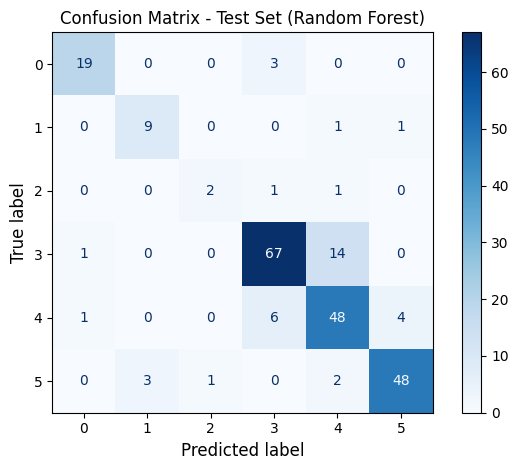

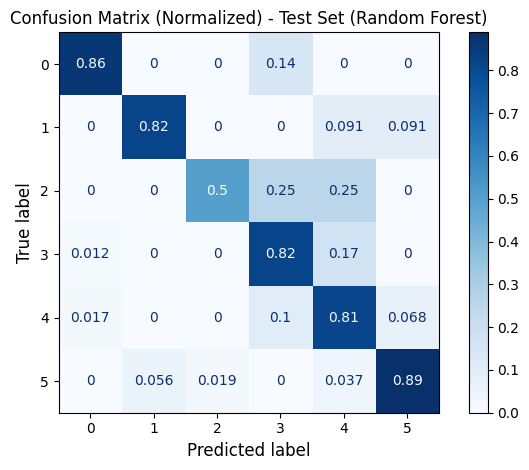

In [44]:
rf_model = RandomForestClassifier(
    random_state=RANDOM_STATE, n_estimators=100, criterion="gini",
    min_samples_leaf=RF_MIN_SAMPLES_LEAF, max_depth=RF_MAX_DEPTH, n_jobs=-1,
)
rf_output = train_evaluate_classifier(X, y, rf_model, "Random Forest")

==================== LightGBM ====================

--- Training samples per suite ---
Label
EqHKCalk    191
PHKCalk     137
Shos        124
Alk          50
Calk         27
ChAlk        10

--- Test samples per suite ---
Label
EqHKCalk    82
PHKCalk     59
Shos        54
Alk         22
Calk        11
ChAlk        4

--- Class balance during resampling (training fold) ---
          before  after_SMOTE  synthetic_added  after_SMOTETomek
Label                                                           
Alk           50          191              141               191
Calk          27          191              164               191
ChAlk         10          191              181               191
EqHKCalk     191          191                0               186
PHKCalk      137          191               54               186
Shos         124          191               67               191

--- Cross-validation (training fold) ---
F1 weighted (mean): 0.8130
F1 weighted (std): 0.0299
AUC OvR (me

,model,precision,recall,f1-score,support
Alk,LightGBM,0.86,0.86,0.86,22.00
Calk,LightGBM,0.77,0.91,0.83,11.00
ChAlk,LightGBM,0.33,0.25,0.29,4.00
EqHKCalk,LightGBM,0.89,0.83,0.86,82.00
PHKCalk,LightGBM,0.76,0.85,0.80,59.00
Shos,LightGBM,0.94,0.91,0.92,54.00
accuracy,LightGBM,0.85,0.85,0.85,0.85
macro avg,LightGBM,0.76,0.77,0.76,232.00
weighted avg,LightGBM,0.85,0.85,0.85,232.00


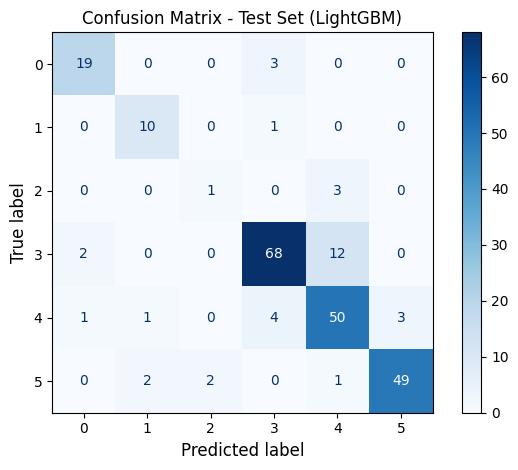

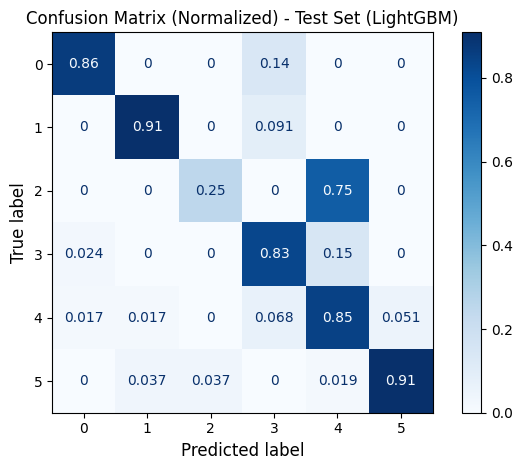

In [45]:
lgbm_model = LGBMClassifier(
    random_state=RANDOM_STATE, n_estimators=100, learning_rate=0.1,
    objective="multiclass", num_class=n_classes, max_depth=LGBM_MAX_DEPTH,
    min_child_samples=LGBM_MIN_CHILD_SAMPLES, subsample=1, colsample_bytree=1,
    verbosity=-1, deterministic=True, force_row_wise=True
)
lgbm_output = train_evaluate_classifier(X, y, lgbm_model, "LightGBM")

In [46]:
rf_report = rf_output["report_df"]
lgbm_report = lgbm_output["report_df"]

classification_reports = pd.concat([rf_report, lgbm_report])
classification_reports.to_excel(PATHS["results_dir"] / "Table3_classification_reports.xlsx")
classification_reports

,model,precision,recall,f1-score,support
Alk,Random Forest,0.904762,0.863636,0.883721,22.000000
Calk,Random Forest,0.750000,0.818182,0.782609,11.000000
ChAlk,Random Forest,0.666667,0.500000,0.571429,4.000000
EqHKCalk,Random Forest,0.870130,0.817073,0.842767,82.000000
PHKCalk,Random Forest,0.727273,0.813559,0.768000,59.000000
Shos,Random Forest,0.905660,0.888889,0.897196,54.000000
accuracy,Random Forest,0.831897,0.831897,0.831897,0.831897
macro avg,Random Forest,0.804082,0.783557,0.790954,232.000000
weighted avg,Random Forest,0.836150,0.831897,0.832775,232.000000
Alk,LightGBM,0.863636,0.863636,0.863636,22.000000


### 4.2. Unsupervised analysis (SOM + K-means)

The unsupervised analysis combined Self-Organising Maps (SOM) for nonlinear dimensionality reduction with K-means clustering, both implemented through the IntraSOM package.

Variables: `VARIABLES_ML` (CLR_OXIDES + SCALED_TRACES + SCALED_INDICES).


`build_som` is the same function defined in Section 2.2 (imputation). Both calls share the same base SOM architecture (toroidal, hexagonal lattice,
variance normalization, gaussian neighborhood) - only `missing` and `name` differ between the two runs. Reusing the function avoids duplicating that
configuration, while still training two fully independent SOMs for two different purposes: one to impute missing values, one for unsupervised
analysis. Because the input data has no missing values (Section 2.2), the SOM trains with `missing=False`.

In [48]:
def plot_umatrix_by_suite(plot, label_series, suites, watermark=False, save=True):
    """Plot the SOM U-matrix once per suite, highlighting the neurons that
    contain at least one representative sample of that suite.
    """
    for suite in suites:
        sample_idx = label_series.index[label_series == suite].tolist()
        plot.plot_umatrix(
            figsize=(8, 7), hits=True,
            title=f"U-Matrix - Labeled Representative Samples of {suite} Label",
            title_size=20, title_pad=20, legend_title="Distance",
            legend_title_size=12, legend_ticks_size=7, label_title_xy=(0, 0.5),
            save=save, file_name=f"U-Matrix - Labeled Representative Samples of {suite} Label",
            file_path=False, watermark_neurons=watermark,
            samples_label=True, samples_label_index=sample_idx,
            samples_label_fontsize=8, save_labels_rep=True,
        )

In [49]:
values_labels = df_final.set_index(df_final["Label"])[VARIABLES_ML]
values_labels.columns

Index(['SiO2-CLR', 'TiO2-CLR', 'Al2O3-CLR', 'Fe2O3-CLR', 'MnO-CLR', 'MgO-CLR',
       'CaO-CLR', 'Na2O-CLR', 'K2O-CLR', 'P2O5-CLR', 'Rb_sc', 'Ba_sc', 'Sr_sc',
       'Nb_sc', 'Zr_sc', 'Y_sc', 'NKC_sc', 'A/NK_sc', 'A/CNK_sc', 'M/MF_sc',
       'FMT_sc', 'K/NK_sc'],
      dtype='str')

Loading dataframe...
Normalizing data...
Creating neighborhood...
Loading distances matrix...
Initializing map...


Creating Neuron Distance Rows:   0%|          | 0/20 [00:00<?, ?rows/s]

Starting Training...
Rough Training:


  0%|          | 0/16 [00:00<?, ?it/s]

Fine Tuning:


  0%|          | 0/26 [00:00<?, ?it/s]

Saving...
Training Report Created
Training completed successfully.


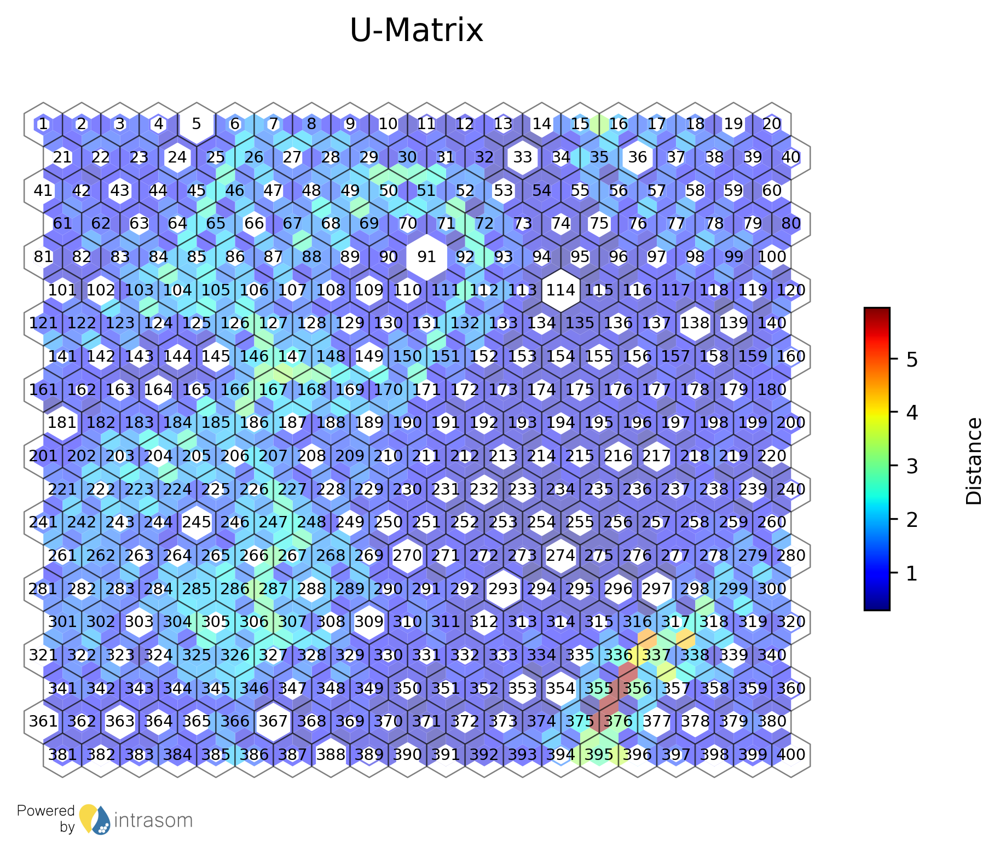

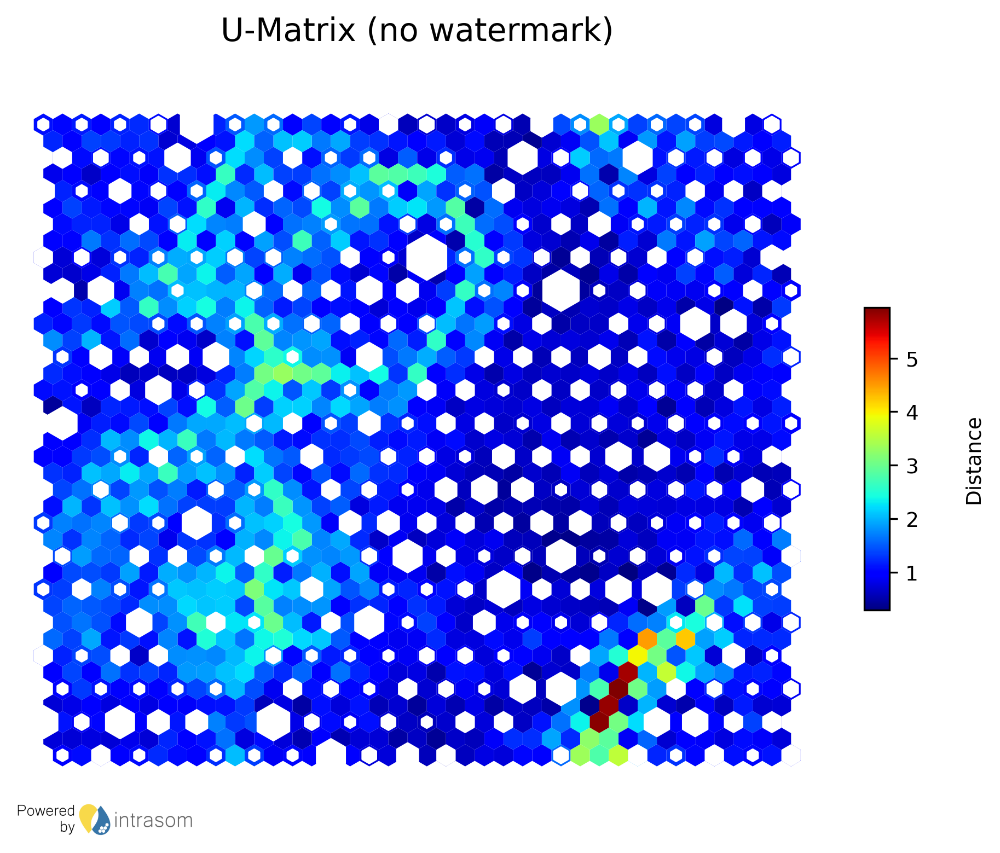

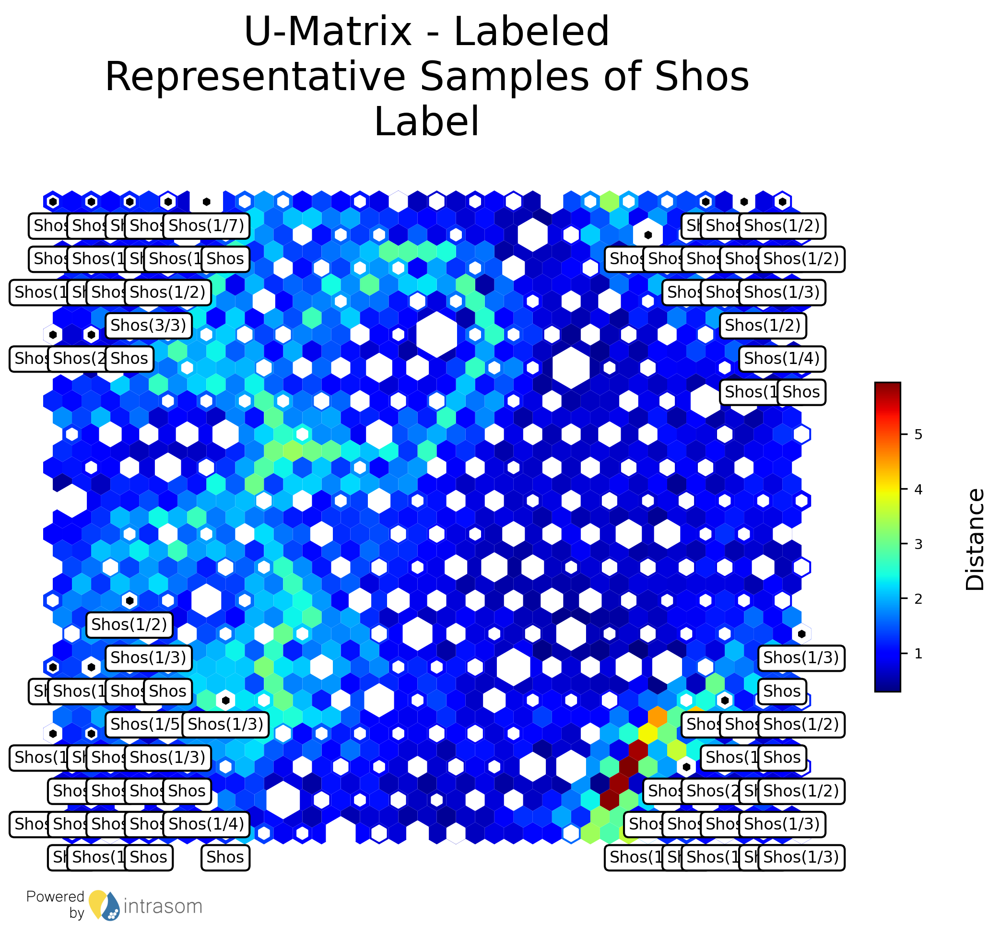

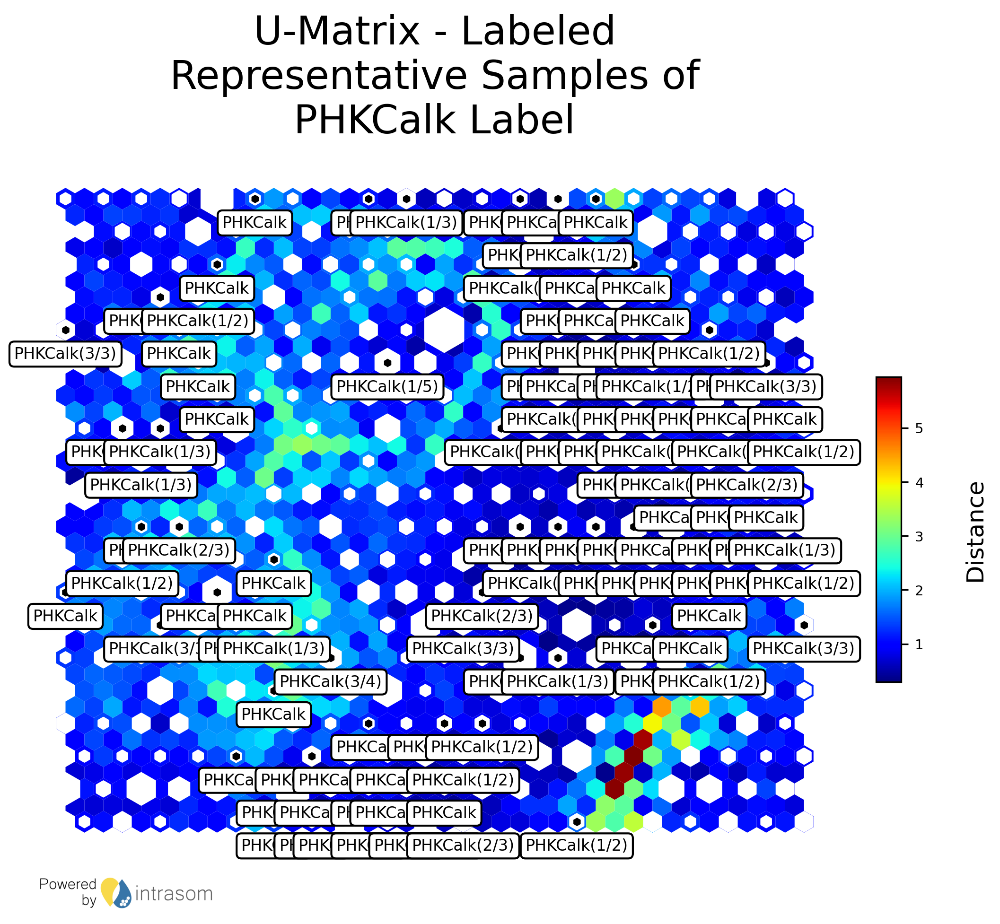

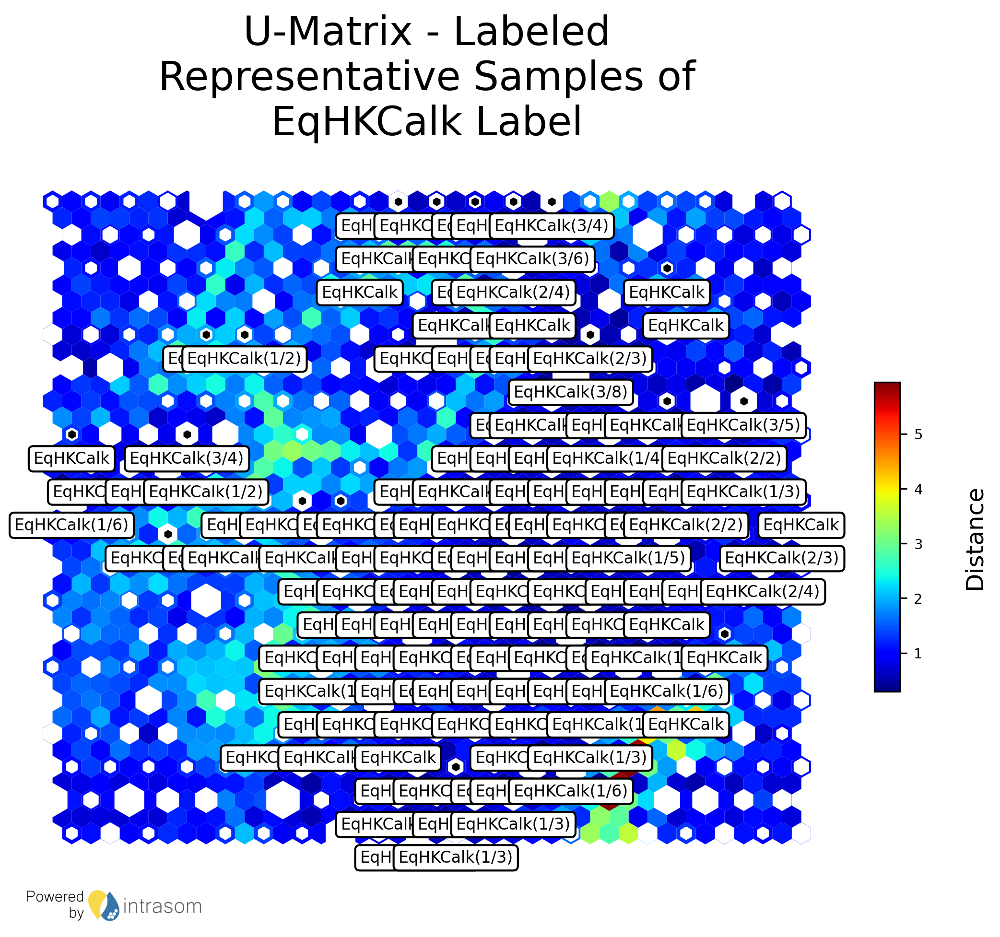

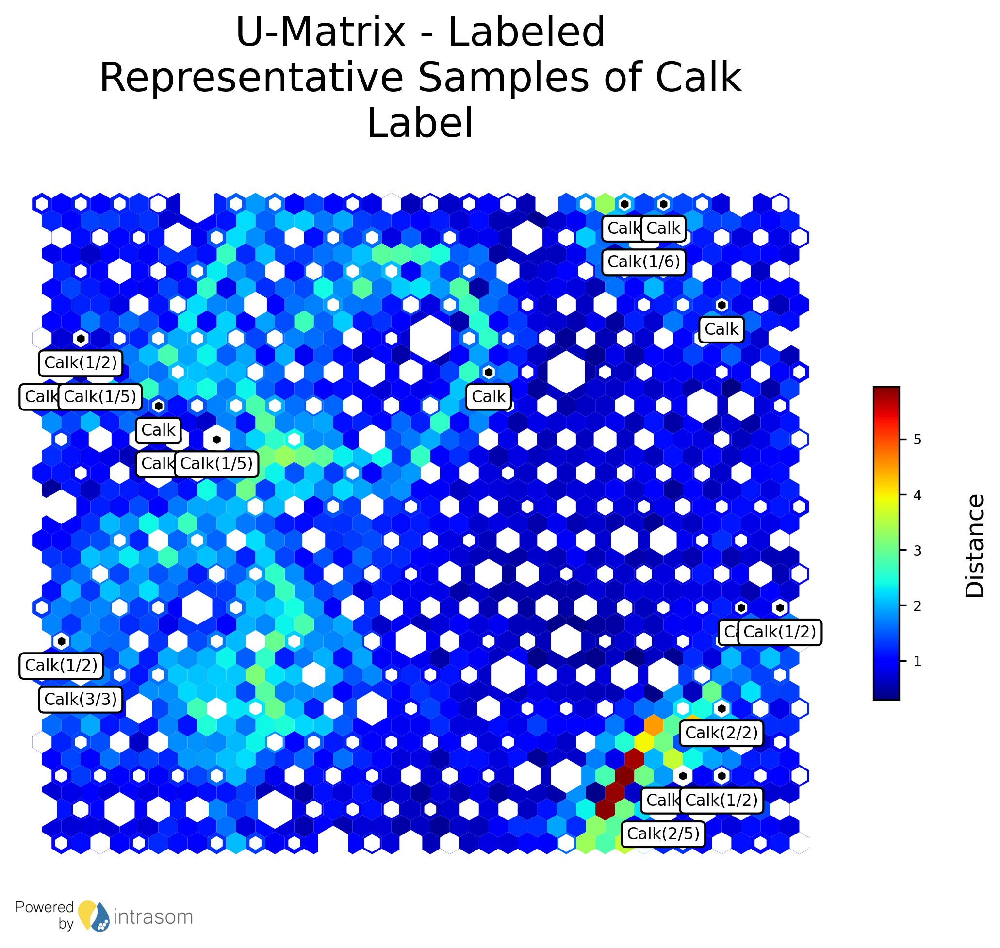

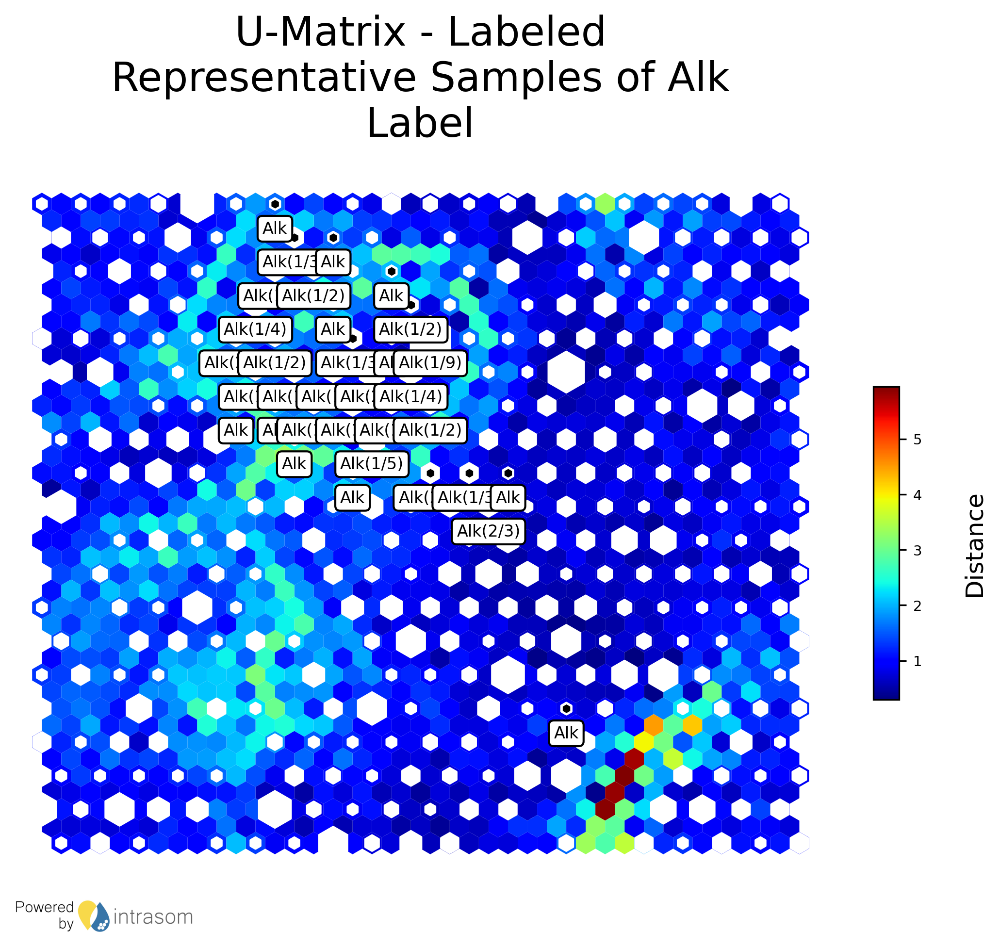

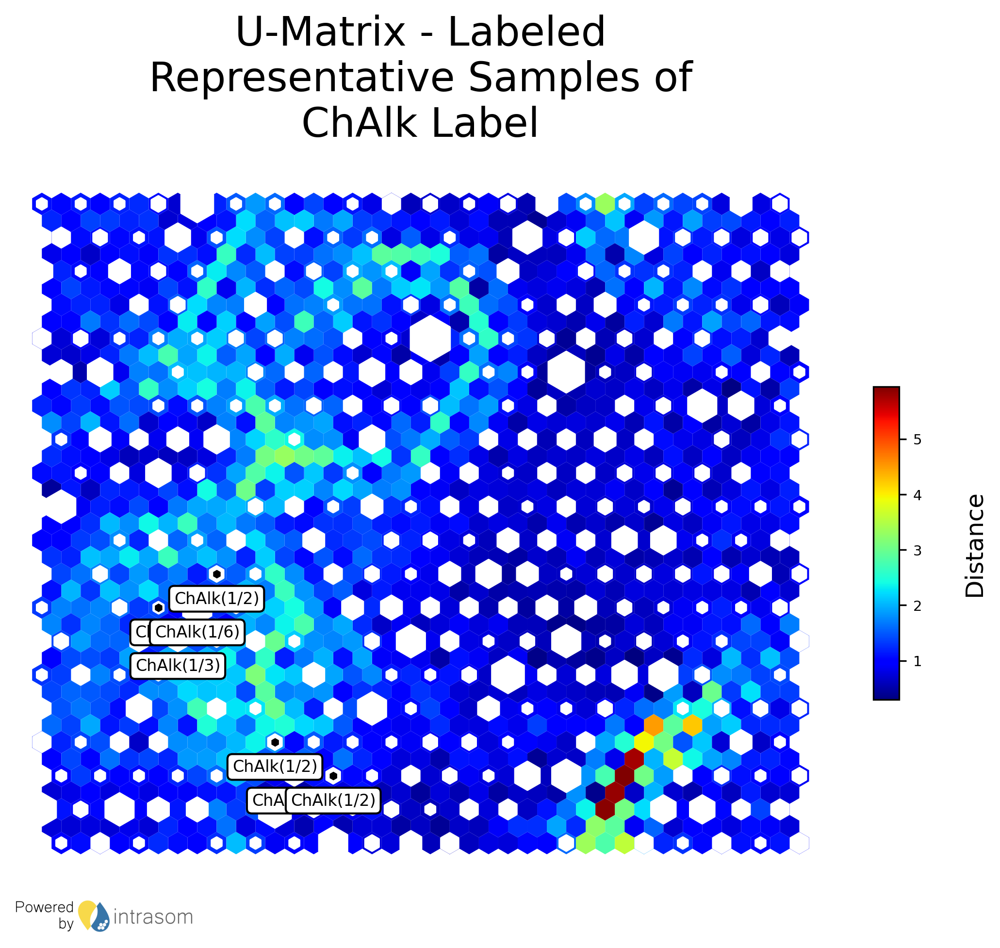

In [50]:
# Run: train final unsupervised SOM model
values_labels = df_final.set_index(df_final["Label"])[VARIABLES_ML]

som_final = build_som(values_labels, mapsize=SOM_MAPSIZE, missing=False, name="granitoids_final")

rep_dic = som_final.rep_sample(save=False)
sorted_rep = dict(sorted(rep_dic.items()))

plot = PlotFactory(som_final)
plot.plot_umatrix(figsize=(7, 6), save=True, watermark_neurons=True, title="U-Matrix",
                   legend_title="Distance", title_size=14, legend_title_size=9, legend_ticks_size=9)
plot.plot_umatrix(figsize=(7, 6), save=True, watermark_neurons=False, title="U-Matrix (no watermark)",
                   legend_title="Distance", title_size=14, legend_title_size=9, legend_ticks_size=9)

# NOTE: `label_series` intentionally keeps its default positional (0..N)
# index here, since `samples_label_index` in IntraSOM's plotting API expects
# row positions into `values_labels`, not the (suite-label) DataFrame index
# that `values_labels` itself uses.

label_series = df_final["Label"].reset_index(drop=True)
plot_umatrix_by_suite(plot, label_series, suites=list(SUITE_COLORS.keys()))

In [51]:
# Run: K-means clustering of the trained SOM model
clustering = ClusterFactory(som_final)
clustering.Davies_Bouldin_analysis(max_clust=10, n_iter=100, save=True)
clustering

100%|██████████| 100/100 [00:21<00:00,  4.57it/s]


Davies-Bouldin results:

First Minimum:
Cluster Number: 2. Percentage: 100.00%.

Second Minimum:
Cluster Number: 5. Percentage: 100.00%.

Third Minimum:
Cluster Number: 10. Percentage: 65.00%.
Cluster Number: 9. Percentage: 21.00%.

Ensemble Minimum:
Cluster Number: 2. Percentage: 50.00%.
Cluster Number: 5. Percentage: 50.00%.


5_clusters
2    257
4    192
1    178
5     78
3     66
Name: count, dtype: int64

Cluster 1 label counts:
Shos        148
Calk         22
PHKCalk       7
EqHKCalk      1
Name: count, dtype: int64

Cluster 2 label counts:
EqHKCalk    205
PHKCalk      45
Alk           5
ChAlk         2
Name: count, dtype: int64

Cluster 3 label counts:
Alk         59
EqHKCalk     5
PHKCalk      1
Calk         1
Name: count, dtype: int64

Cluster 4 label counts:
PHKCalk     109
EqHKCalk     60
Calk         14
Shos          5
Alk           4
Name: count, dtype: int64

Cluster 5 label counts:
PHKCalk     34
Shos        25
ChAlk       12
Alk          4
EqHKCalk     2
Calk         1
Name: count, dtype: int64


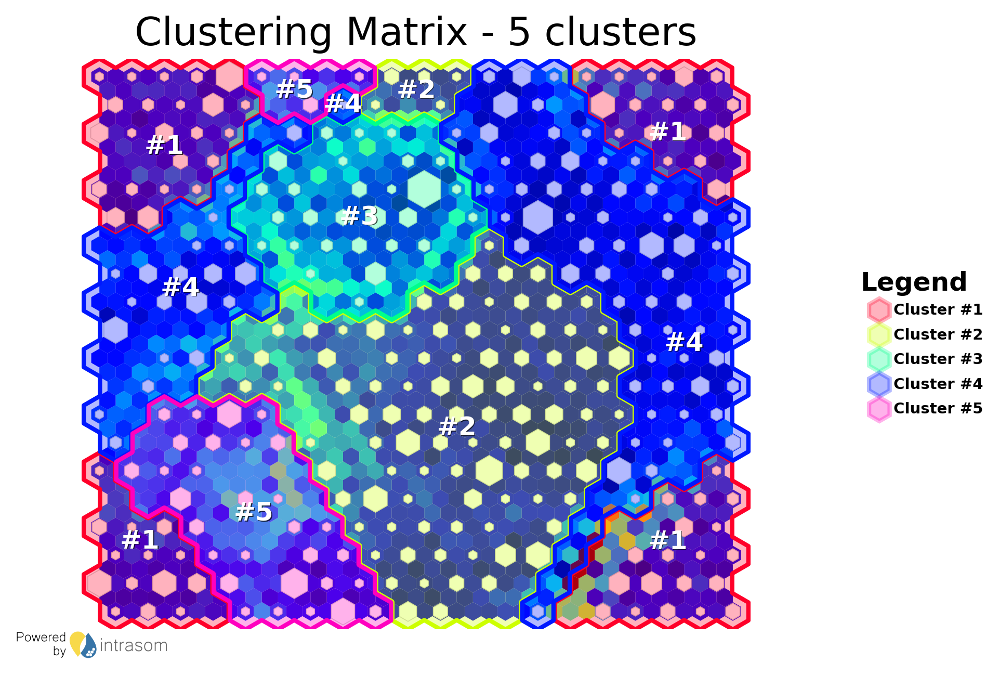

In [52]:
N_CLUSTERS = 5  # selected from the Davies-Bouldin analysis above
clusters = clustering.kmeans(k=N_CLUSTERS)
np.save(PATHS["results_dir"] / "neurons_5_clusters.npy", clusters)
clustering.plot_kmeans(
    figsize=(8, 5), clusters=clusters, title_size=18, title_pad=20, umatrix=True,
    colormap="gist_rainbow", alfa_clust=0.3, hits=True, legend_text_size=7,
    cluster_outline=True, save=True, file_name="clustering", plot_labels=True,
)

clusters_df = clustering.results_cluster(clusters)
cluster_col = f"{N_CLUSTERS}_clusters"
print(clusters_df[cluster_col].value_counts())

for cluster_num in sorted(clusters_df[cluster_col].unique()):
    counts = clusters_df.loc[clusters_df[cluster_col] == cluster_num].index.value_counts()
    print(f"\nCluster {cluster_num} label counts:\n{counts}")

In [53]:
# Run: component plots + consolidated results 
plot.component_plot_collage(
    figsize=(10, 10), grid=(4, 4), title_size=20, legend_title="", legend_pad=5,
    legend_title_size=12, legend_ticks_size=10, label_title_xy=(0, 0.7),
    wich=list(range(values_labels.shape[1])),
)

df_som_results = pd.concat([
    som_final.results_dataframe.reset_index(drop=True),
    clusters_df[cluster_col].reset_index(drop=True),
    df_final.reset_index(drop=True),
], axis=1)

df_som_results.to_excel(PATHS["results_dir"] / "Original_data_and_results_IntraSOM.xlsx", index=False)
print("Final SOM+clustering results shape:", df_som_results.shape)
df_som_results.head()

Generating maps...


  0%|          | 0/22 [00:00<?, ?it/s]

Finished
Generating collage...
Finished.
Final SOM+clustering results shape: (771, 122)


,BMU,q-error,Udist,Ret_x,Ret_y,Cub_x,Cub_y,Cub_z,B_SiO2-CLR,B_TiO2-CLR,...,corundum-CLR,magnetite-CLR,hematite-CLR,forsterite-CLR,fayalite-CLR,clinoferrosilite-CLR,clinoenstatite-CLR,ferrosilite-CLR,enstatite-CLR,wollastonite-CLR
0,377,3.090739,0.338700,16,18,7,-25,18,2.832216,-0.848972,...,-8.657124,4.644222,-8.657124,5.070429,4.455996,4.616758,5.465503,-8.657124,-8.657124,-8.657124
1,381,1.987600,0.197225,0,19,-9,-10,19,2.629618,-0.625285,...,-9.295301,4.243928,-9.295301,3.189539,2.856843,2.171580,2.738796,3.798662,4.228385,-9.295301
2,378,1.694145,0.159913,17,18,8,-26,18,2.744454,-0.735207,...,-9.336355,4.050984,-9.336355,3.524384,3.407088,3.867588,4.219088,3.140889,3.354918,-9.336355
3,379,1.851783,0.197980,18,18,9,-27,18,2.678380,-0.651362,...,-9.282709,4.016796,-9.282709,3.840854,3.510039,3.897735,4.462916,2.404170,2.831797,-9.282709
4,378,2.930271,0.159913,17,18,8,-26,18,2.744454,-0.735207,...,-9.251928,4.106929,-9.251928,2.555158,2.658430,4.096614,4.227130,4.065673,4.059070,-9.251928


#### Contingency table (pre-defined magmatic suites vs. unsupervised clusters)

Contingency table (counts):
 Label       Alk  Calk  ChAlk  EqHKCalk  PHKCalk  Shos
5_clusters                                           
1             0    22      0         1        7   148
2             5     0      2       205       45     0
3            59     1      0         5        1     0
4             4    14      0        60      109     5
5             4     1     12         2       34    25

Suite composition within each cluster (rows sum to 1):
 Label            Alk      Calk     ChAlk  EqHKCalk   PHKCalk      Shos
5_clusters                                                            
1           0.000000  0.123596  0.000000  0.005618  0.039326  0.831461
2           0.019455  0.000000  0.007782  0.797665  0.175097  0.000000
3           0.893939  0.015152  0.000000  0.075758  0.015152  0.000000
4           0.020833  0.072917  0.000000  0.312500  0.567708  0.026042
5           0.051282  0.012821  0.153846  0.025641  0.435897  0.320513

Cluster composition within each suite 

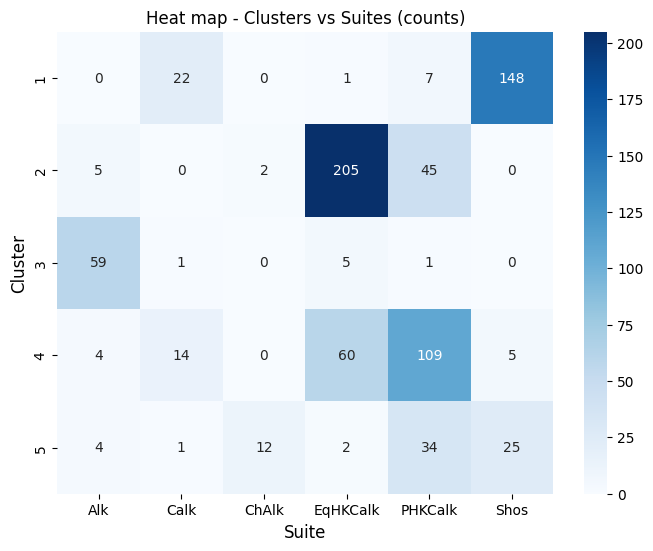

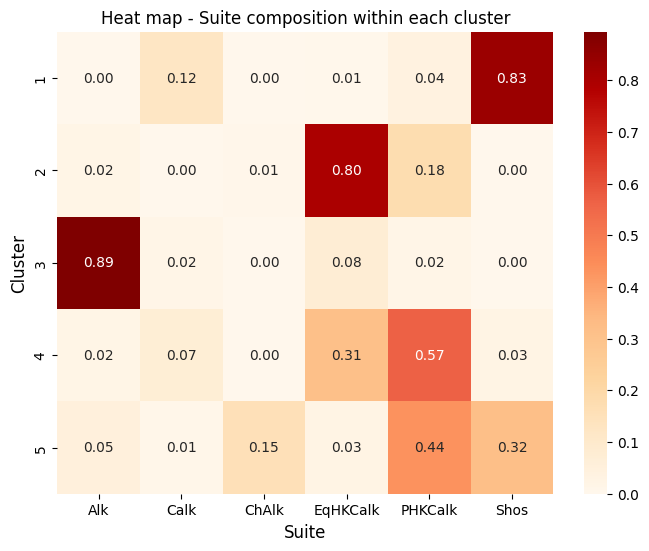

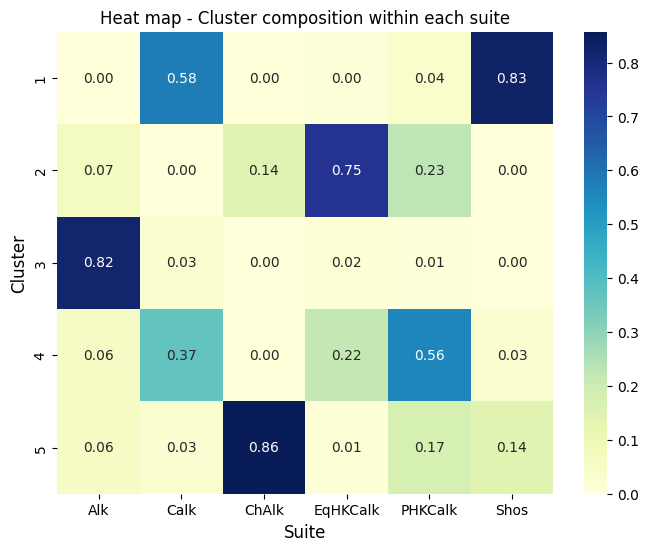

In [55]:
def contingency_analysis(df, cluster_col, label_col="Label"):
    """Print/plot a contingency table and two normalized heatmaps between
    SOM clusters and pre-defined suite labels: suite composition within
    each cluster, and cluster composition within each suite.
    """
    table = pd.crosstab(df[cluster_col], df[label_col])  # rows: cluster, cols: suite

    suite_composition_per_cluster = table.div(table.sum(axis=1), axis=0)  # rows sum to 1
    cluster_composition_per_suite = table.div(table.sum(axis=0), axis=1)  # columns sum to 1

    print("Contingency table (counts):\n", table)
    print("\nSuite composition within each cluster (rows sum to 1):\n", suite_composition_per_cluster)
    print("\nCluster composition within each suite (columns sum to 1):\n", cluster_composition_per_suite)

    plt.figure(figsize=(8, 6))
    sns.heatmap(table, annot=True, fmt="d", cmap="Blues")
    plt.title("Heat map - Clusters vs Suites (counts)")
    plt.xlabel("Suite")
    plt.ylabel("Cluster")
    plt.show()

    plt.figure(figsize=(8, 6))
    sns.heatmap(suite_composition_per_cluster, annot=True, fmt=".2f", cmap="OrRd")
    plt.title("Heat map - Suite composition within each cluster")
    plt.xlabel("Suite")
    plt.ylabel("Cluster")
    plt.show()

    plt.figure(figsize=(8, 6))
    sns.heatmap(cluster_composition_per_suite, annot=True, fmt=".2f", cmap="YlGnBu")
    plt.title("Heat map - Cluster composition within each suite")
    plt.xlabel("Suite")
    plt.ylabel("Cluster")
    plt.show()

    return table
_ = contingency_analysis(df_som_results, cluster_col=cluster_col, label_col="Label")

#### Template neurons by pre-defined magmatic suite

Static hexagonal-grid outlines highlighting the neurons dominated by each suite previously defined in the study area and evaluated in this work, used
as annotated figure templates in the manuscript. Which neurons belong to each suite is derived automatically below from the trained SOM's own best-matching-unit (BMU) assignment per sample — not a hand-typed list — so this regenerates correctly every time the SOM is retrained, without manual
re-inspection.

In [57]:
def _hexagon_vertices(x, y, r):
    angles = np.linspace(0, 2 * np.pi, 7)[:-1] + np.pi / 6
    return [(x + r * np.cos(a), y + r * np.sin(a)) for a in angles]


def _merge_hexagon_outlines(highlighted_edges):
    """Trace the outer boundary of a set of contiguous highlighted hexagons
    by keeping only edges that are not shared between two highlighted cells.
    """
    outer_edges = [list(e) for e, count in highlighted_edges.items() if count == 1]
    contours = []
    while outer_edges:
        contour = [outer_edges[0][0], outer_edges[0][1]]
        outer_edges.pop(0)
        changed = True
        while changed:
            changed = False
            for i, (p1, p2) in enumerate(outer_edges):
                if np.allclose(contour[-1], p1):
                    contour.append(p2)
                elif np.allclose(contour[-1], p2):
                    contour.append(p1)
                else:
                    continue
                outer_edges.pop(i)
                changed = True
                break
        contours.append(contour)
    return contours


def plot_som_template_panel(ax, mapsize=SOM_MAPSIZE, highlight_neurons=(), color="green", lw=2.5, merge=True):
    """Draw the SOM hexagonal grid outline on a given axis, optionally
    highlighting a set of neurons with a merged colored outline.

    `highlight_neurons` uses 1-based neuron indices (as reported by
    `som.rep_sample`); they are converted to 0-based internally.
    """
    highlight_neurons = np.array(highlight_neurons) - 1 if len(highlight_neurons) else np.array([])
    n_rows, n_cols = mapsize
    hex_radius = 1.0
    dx = np.sqrt(3) * hex_radius
    dy = 1.5 * hex_radius

    ax.set_aspect("equal")
    highlighted_edges = {}
    for i in range(n_rows):
        for j in range(n_cols):
            idx = i * n_cols + j
            x = j * dx + (dx / 2 if i % 2 == 1 else 0)
            y = i * dy
            is_hl = idx in highlight_neurons

            hexagon = RegularPolygon(
                (x, -y), numVertices=6, radius=hex_radius, orientation=0,
                edgecolor=("none" if merge else color) if is_hl else "black",
                facecolor="none", linewidth=(lw if is_hl else 1),
            )
            ax.add_patch(hexagon)

            if is_hl:
                verts = _hexagon_vertices(x, -y, hex_radius)
                for k in range(6):
                    p1 = tuple(np.round(verts[k], 5))
                    p2 = tuple(np.round(verts[(k + 1) % 6], 5))
                    edge = tuple(sorted([p1, p2]))
                    highlighted_edges[edge] = highlighted_edges.get(edge, 0) + 1

    if merge:
        for contour in _merge_hexagon_outlines(highlighted_edges):
            ax.add_patch(Polygon(contour, closed=True, fill=False, edgecolor=color,
                                  linewidth=lw, joinstyle="round"))

    ax.set_xlim(-hex_radius - 0.5, n_cols * dx + hex_radius)
    ax.set_ylim(-n_rows * dy - hex_radius, hex_radius + 0.5)
    ax.axis("off")

In [58]:
# --- Run: detect which neurons belong to each suite, from the trained SOM ---
candidate_cols = [c for c in df_som_results.columns if "bmu" in c.lower() or "neuron" in c.lower()]

if len(candidate_cols) == 1:
    bmu_col = candidate_cols[0]
    print(f"Auto-detected BMU column: '{bmu_col}'")
elif len(candidate_cols) > 1:
    raise ValueError(
        f"Multiple possible BMU columns found: {candidate_cols}. "
        "Set `bmu_col` manually to the correct one."
    )
else:
    print("Could not auto-detect a BMU column. Available columns:")
    print(list(df_som_results.columns))
    raise ValueError("Set `bmu_col` manually, then re-run this cell.")

# IntraSOM's BMU indices are 0-based internally; plot_som_template_panel
# expects 1-based neuron numbers (it subtracts 1 internally). Adjust
# `bmu_is_zero_indexed` below if this does not match what you see when
# comparing against `sorted_rep` from Section 4.2.
bmu_is_zero_indexed = True
offset = 1 if bmu_is_zero_indexed else 0

SUITE_TEMPLATE_NEURONS = {
    suite: sorted(df_som_results.loc[df_som_results["Label"] == suite, bmu_col].unique() + offset)
    for suite in df_som_results["Label"].unique()
}

for suite, neurons in SUITE_TEMPLATE_NEURONS.items():
    print(f"{suite}: {len(neurons)} neurons")

Auto-detected BMU column: 'BMU'
Shos: 78 neurons
EqHKCalk: 133 neurons
PHKCalk: 111 neurons
Calk: 19 neurons
ChAlk: 7 neurons
Alk: 33 neurons


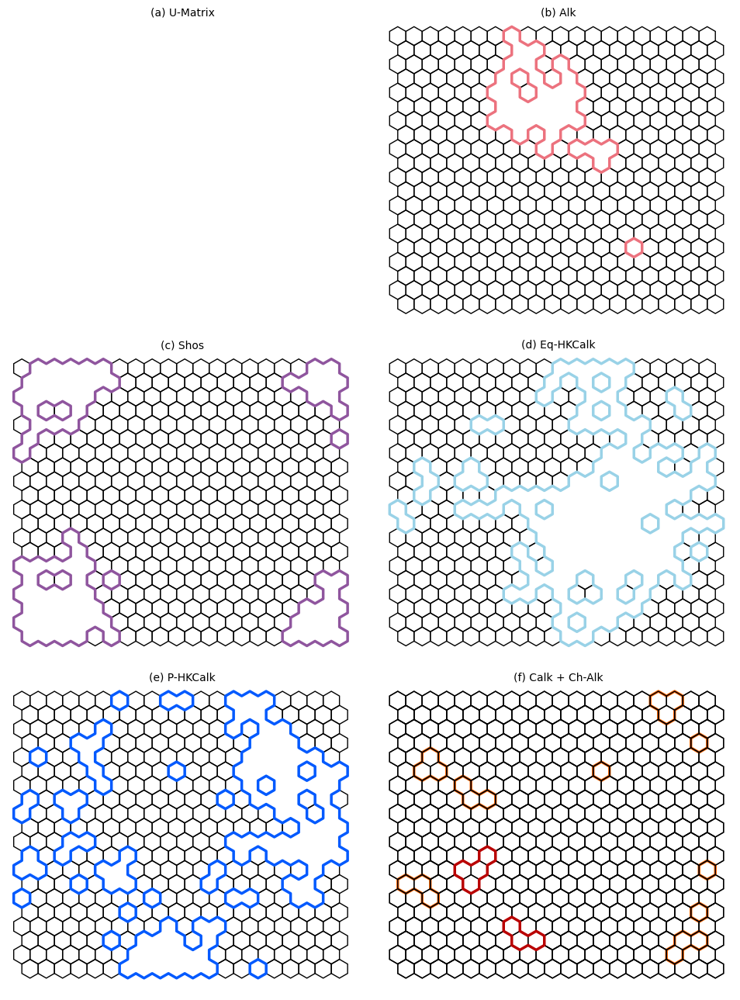

In [59]:
# --- Run: 6-panel figure (A blank for U-matrix; B-F template outlines) ------
fig, axs = plt.subplots(3, 2, figsize=(10, 13))

panels = [
    ("a", "U-Matrix", None),
    ("b", "Alk", ["Alk"]),
    ("c", "Shos", ["Shos"]),
    ("d", "Eq-HKCalk", ["EqHKCalk"]),
    ("e", "P-HKCalk", ["PHKCalk"]),
    ("f", "Calk + Ch-Alk", ["Calk", "ChAlk"]),
]

for ax, (label, title, suites) in zip(axs.ravel(), panels):
    if suites is None:
        # Panel (a) intentionally left blank - U-matrix added separately.
        ax.set_aspect("equal")
        ax.axis("off")
    else:
        for suite in suites:
            plot_som_template_panel(
                ax, mapsize=SOM_MAPSIZE, highlight_neurons=SUITE_TEMPLATE_NEURONS[suite],
                color=SUITE_COLORS[suite], lw=2.5, merge=True,
            )
    ax.set_title(f"({label}) {title}", fontsize=10)

plt.tight_layout()
plt.savefig(PATHS["figures_dir"] / "SOM_template_6panel.pdf", dpi=300, bbox_inches="tight")
plt.show()

## 5. PCA: pre-defined magmatic suites vs. unsupervised clusters

The same `_plot_pca_biplot` helper from Section 3 is reused here to combine both PCA results — (a) colored by pre-defined suite (Label) and
(b) colored by SOM cluster (matching the `gist_rainbow` colormap used in the K-means plot, Section 4.2) — into a single side-by-side figure.

In [61]:
def plot_pca_pair(df, panels, max_width_mm=174, height_mm=100, save_path=None):
    """Two PCA biplots side by side (1x2), sized to the journal's maximum figure width.
    
    Parameters
    ----------
    panels : list of dict, length 2
        Each dict: {"variables": [...], "hue_col": ..., "palette": {...},
        "title": ..., "panel_label": "a"/"b"}
    """
    mm_to_in = 1 / 25.4
    figsize = (max_width_mm * mm_to_in, height_mm * mm_to_in)

    fig, axes = plt.subplots(1, 2, figsize=figsize)
    results = {}

    for ax, panel in zip(axes, panels):
        variables = panel["variables"]
        hue_col = panel["hue_col"]
        palette = panel["palette"]

        pca = PCA()
        pcs = pca.fit_transform(df[variables])
        variance_pct = pca.explained_variance_ratio_ * 100
        loadings = pca.components_

        _plot_pca_biplot(
            ax, pcs, loadings, variables, variance_pct, df[hue_col], palette,
            loading_scale=panel.get("loading_scale", 3), panel_label=panel.get("panel_label"),
        )
        ax.set_title(panel["title"], fontsize=9)
        ax.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, -0.16),
                  ncol=2, frameon=False)

        eigen_df = pd.DataFrame({
            "Principal component": [f"PC{i + 1}" for i in range(len(pca.explained_variance_))],
            "Eigenvalue": pca.explained_variance_,
            "Variance (%)": variance_pct,
            "Cumulative variance (%)": np.cumsum(variance_pct),
        })
        loadings_df = pd.DataFrame(
            loadings.T, columns=[f"PC{i + 1}" for i in range(pca.n_components_)], index=variables,
        )
        results[panel["panel_label"]] = {"eigen": eigen_df, "loadings": loadings_df}

        print(f"\n=== PCA: panel ({panel['panel_label']}) - {panel['title']} ===")
        print(eigen_df.to_string(index=False))
        print("\nLoadings (PC1, PC2):")
        print(loadings_df[["PC1", "PC2"]].round(3))

    fig.subplots_adjust(left=0.08, right=0.96, top=0.90, bottom=0.24, wspace=0.35)
    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    return results


=== PCA: panel (a) - By pre-defined suite ===
Principal component   Eigenvalue  Variance (%)  Cumulative variance (%)
                PC1 6.872201e+00  4.506577e+01                45.065774
                PC2 2.512220e+00  1.647437e+01                61.540140
                PC3 1.686448e+00  1.105920e+01                72.599343
                PC4 9.805099e-01  6.429882e+00                79.029225
                PC5 6.782908e-01  4.448022e+00                83.477247
                PC6 5.487898e-01  3.598794e+00                87.076041
                PC7 4.514585e-01  2.960525e+00                90.036566
                PC8 3.999935e-01  2.623034e+00                92.659600
                PC9 3.266259e-01  2.141912e+00                94.801512
               PC10 2.367483e-01  1.552522e+00                96.354035
               PC11 1.637760e-01  1.073993e+00                97.428027
               PC12 1.097745e-01  7.198676e-01                98.147895
               PC

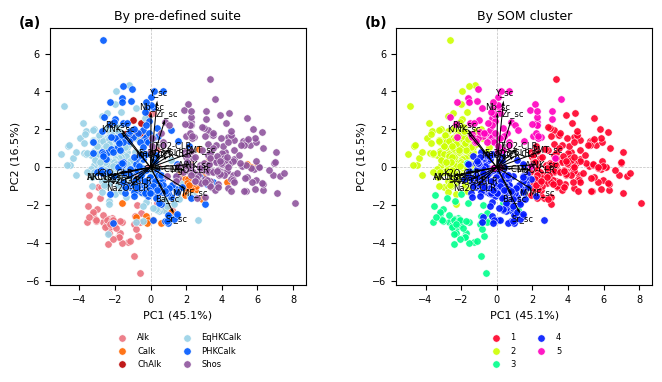

In [62]:
cluster_ids = sorted(df_som_results[cluster_col].unique())
cmap = plt.get_cmap("gist_rainbow")
cluster_palette = {
    cid: cmap(i / max(len(cluster_ids) - 1, 1)) for i, cid in enumerate(cluster_ids)
}

pca_som_results = plot_pca_pair(
    df_som_results,
    panels=[
        {
            "variables": VARIABLES_ML, "hue_col": "Label", "palette": suite_palette,
            "title": "By pre-defined suite", "panel_label": "a", "loading_scale": 7,
        },
        {
            "variables": VARIABLES_ML, "hue_col": cluster_col, "palette": cluster_palette,
            "title": "By SOM cluster", "panel_label": "b", "loading_scale": 7,
        },
    ],
    save_path=PATHS["figures_dir"] / "PCA_SOM_and_Labels_combined.pdf",
)

In [63]:
def summarize_by_cluster(df, cluster_col, variables, save_path=None):
    """min / mean / max summary of `variables`, one column per cluster."""
    summary = {}
    for cluster_val in sorted(df[cluster_col].unique()):
        subset = df.loc[df[cluster_col] == cluster_val, variables]
        agg = subset.agg(["min", "mean", "max"]).T
        summary[cluster_val] = agg.apply(
            lambda x: f"{x['min']:.3f} / {x['mean']:.3f} / {x['max']:.3f}", axis=1
        )
    table = pd.DataFrame(summary)
    table.index.name = "Variable"
    if save_path is not None:
        table.to_excel(save_path)
    return table

In [64]:
#Run: summary statistics
summary_vars = OXIDES + TRACE_ELEMENTS + GEOCHEM_INDICES
summary_table = summarize_by_cluster(
    df_som_results, cluster_col=cluster_col, variables=summary_vars,
    save_path=PATHS["results_dir"] / "Table4_summary_statistics_by_cluster.xlsx",
)
summary_table.head()

,1,2,3,4,5
Variable,,,,,
SiO2,46.700 / 56.290 / 67.850,68.030 / 73.153 / 78.770,66.570 / 71.868 / 76.860,58.670 / 68.818 / 73.600,54.150 / 64.652 / 72.470
TiO2,0.460 / 1.413 / 3.150,0.020 / 0.218 / 0.710,0.020 / 0.103 / 0.320,0.100 / 0.418 / 1.010,0.060 / 0.810 / 2.260
Al2O3,9.830 / 15.996 / 19.780,10.590 / 13.733 / 16.260,12.540 / 15.066 / 16.750,13.400 / 15.269 / 19.730,11.540 / 15.206 / 18.250
Fe2O3,4.060 / 8.670 / 14.890,0.440 / 2.064 / 3.860,0.210 / 1.187 / 3.040,0.950 / 2.995 / 6.690,2.070 / 5.751 / 12.470
MnO,0.050 / 0.124 / 0.260,0.008 / 0.037 / 0.190,0.010 / 0.038 / 0.110,0.010 / 0.040 / 0.120,0.040 / 0.193 / 2.630


## 6. Geochemical Figures

The finalized bivariate diagrams used in the work, in two groups:

- **Figures 2A-2E** — petrological classification diagrams (adapted from
  the literature cited in each figure's title), each with fixed boundary
  lines and field labels that must not be altered.
- **Figures 3A-3F** — simple trace-element vs. SiO2 compositional trend
  plots (Ba, Rb, Sr, Zr, Nb, Y), no classification boundaries.

Each figure is generated twice: once colored by the pre-defined suite
(Label) and once by the SOM cluster, so both groupings can be compared
directly. 

Shared axis/tick styling (`_style_axes`) and point-drawing
(`_scatter_by_group`) are centralized to avoid repeating that boilerplate
across eleven near-identical figures.

**Note on grouping:** in the manuscript, Figures 2 and 3 are presented
colored only by the pre-defined suite (Label), consistent with the
figure numbering and captions used there. The cluster-colored versions
generated here are additional, exploratory outputs — included to compare
how the SOM+K-means clustering result relates to the field-based suite
classification directly in composition space, not for inclusion in the
manuscript itself.

In [66]:
def _style_axes(ax, x_major=None, x_minor=None, y_major=None, y_minor=None):
    """Shared tick/label styling used by all bivariate figures in this chapter."""
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1f}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.1f}"))
    ax.minorticks_on()
    ax.tick_params(axis="both", which="minor", length=3, color="k")
    ax.tick_params(axis="both", which="major", length=6, width=1, color="k")
    if x_major: ax.xaxis.set_major_locator(plt.MultipleLocator(x_major))
    if x_minor: ax.xaxis.set_minor_locator(plt.MultipleLocator(x_minor))
    if y_major: ax.yaxis.set_major_locator(plt.MultipleLocator(y_major))
    if y_minor: ax.yaxis.set_minor_locator(plt.MultipleLocator(y_minor))


def _scatter_by_group(ax, df, x_col, y_col, group_col, palette):
    for group, color in palette.items():
        subset = df[df[group_col] == group]
        ax.scatter(subset[x_col], subset[y_col], facecolor=color, label=group,
                   edgecolor="white", marker="o", s=45, alpha=1, zorder=4)
        
def _finalize_figure(fig, ax, legend_title=None):
    """Fix the plotting (data) area to a constant, square size and place the
    legend outside it, at a fixed position."""
    ax.set_box_aspect(1)
    fig.subplots_adjust(left=0.16, right=0.72, top=0.90, bottom=0.13)
    if ax.get_legend_handles_labels()[0]:
        ax.legend(title=legend_title, fontsize=8, bbox_to_anchor=(1.03, 1),
                  loc="upper left", frameon=False)

In [67]:
def plot_k2o_vs_sio2(df, group_col, palette, save_path=None):
    """K2O vs SiO2 classification diagram (modified from Jacob et al., 2021)."""
    fig, ax = plt.subplots(figsize=(5, 5))
    _scatter_by_group(ax, df, "SiO2", "K2O", group_col, palette)

    lines = [
        ([48, 52, 56, 63, 70, 78], [0.3, 0.5, 0.7, 1, 1.3, 1.6], "gray", "dotted"),
        ([48, 52, 56, 63, 70], [1.2, 1.5, 1.8, 2.4, 3], "gray", "dotted"),
        ([48, 52, 56, 63], [1.6, 2.4, 3.2, 4], "gray", "dotted"),
        ([50, 70], [1.75, 6.25], "black", "solid"),
        ([55, 70], [1, 4], "black", "solid"),
        ([65, 80], [1, 4], "black", "solid"),
        ([70, 70, 80], [8, 4, 4], "black", "solid"),
    ]
    for x, y, color, style in lines:
        ax.plot(x, y, color=color, linewidth=0.8, linestyle=style)

    for x, y, txt, rot in [(60, 5.0, "Ultra High-K", 45), (63, 3.5, "High-K", 45), (65, 2.0, "Medium-K", 45)]:
        ax.text(x, y, txt, ha="center", va="center", fontsize=12, color="k", rotation=rot)

    ax.set_title("Modified from Jacob et al. (2021)", fontsize=14)
    ax.set_xlabel("SiO$_2$ (wt%)", fontsize=14)
    ax.set_ylabel("K$_2$O (wt%)", fontsize=14)
    _style_axes(ax, x_major=10, x_minor=10, y_major=2, y_minor=2)
    _finalize_figure(fig, ax, legend_title="Class")
    if save_path is not None:
        plt.savefig(save_path)
    plt.show()


def plot_alkalinity_index(df, group_col, palette, save_path=None):
    """Na2O+K2O-CaO vs SiO2 alkalinity classification (Frost et al., 2001 modified by Jacob et al., 2021)."""
    df = df.copy()
    df["INDEX2"] = df["Na2O"] + df["K2O"] - df["CaO"]

    fig, ax = plt.subplots(figsize=(5, 5))
    _scatter_by_group(ax, df, "SiO2", "INDEX2", group_col, palette)

    sio2_range = np.linspace(45, 80)
    ax.plot(sio2_range, -41.86 + 1.112 * sio2_range - 0.00572 * sio2_range ** 2, "k--", linewidth=0.7)
    ax.plot(sio2_range, -44.72 + 1.094 * sio2_range - 0.00527 * sio2_range ** 2, "k--", linewidth=0.7)
    ax.plot(sio2_range, -45.36 + 1.0043 * sio2_range - 0.00427 * sio2_range ** 2, "k--", linewidth=0.7)
    ax.axvline(x=70, color="gray", linestyle="--", linewidth=0.7)

    for x, y, txt, rot in [(50, 0.9, "Alkalic", 45), (55, 0.1, "Alkali-calcic", 40),
                            (60, 0.1, "Calc-alkalic", 38), (65, 0.1, "Calcic", 40)]:
        ax.text(x, y, txt, ha="center", va="center", fontsize=12, color="k", rotation=rot)

    ax.set_title("Frost et al. (2001)", fontsize=14)
    ax.set_xlabel("SiO$_2$ (wt%)", fontsize=14)
    ax.set_ylabel("Na$_2$O + K$_2$O - CaO", fontsize=14)
    _style_axes(ax, x_major=10, x_minor=10, y_major=5, y_minor=5)
    _finalize_figure(fig, ax, legend_title="Class")
    if save_path is not None:
        plt.savefig(save_path)
    plt.show()


def plot_shand_index(df, group_col, palette, save_path=None):
    """A/NK vs A/CNK (Shand Index; Maniar & Piccoli, 1989)."""
    df = df.copy()
    df["ANK"] = (df["Al2O3"] / 101.96) / ((df["Na2O"] / 61.98) + (df["K2O"] / 94.20))
    df["ACNK"] = (df["Al2O3"] / 101.96) / (
        (df["CaO"] / 56.08) + (df["Na2O"] / 61.98) + (df["K2O"] / 94.20)
    )

    fig, ax = plt.subplots(figsize=(5, 5))
    _scatter_by_group(ax, df, "ACNK", "ANK", group_col, palette)
    ax.axhline(1, color="gray", linewidth=0.7)
    ax.axvline(1, color="gray", linewidth=0.7)

    for x, y, txt in [(0.7, 1.5, "Metaluminous"), (1.2, 1.5, "Peraluminous"), (0.7, 0.94, "Peralkaline")]:
        ax.text(x, y, txt, ha="center", va="center", fontsize=12, color="k")

    ax.set_title("Shand Index (Maniar & Piccoli, 1989)", fontsize=14)
    ax.set_xlabel("Al$_2$O$_3$ / (CaO + Na$_2$O + K$_2$O)", fontsize=14)
    ax.set_ylabel("Al$_2$O$_3$ / (Na$_2$O + K$_2$O)", fontsize=14)
    _style_axes(ax, x_major=1, x_minor=0.2, y_major=1, y_minor=0.2)
    _finalize_figure(fig, ax, legend_title="Legend")
    if save_path is not None:
        plt.savefig(save_path)
    plt.show()

def plot_femgti_vs_mgfe(df, group_col, palette, save_path=None):
    """Fe+Mg+Ti vs Mg/(Mg+Fe) (Debon and Le Fort, 1983)."""
    df = df.copy()
    df["FeOT"] = df["Fe2O3"] * 0.89981
    df["Fe_m"] = df["FeOT"] / 71.839 * 1000
    df["Mg_m"] = df["MgO"] / 40.299 * 1000
    df["Ti_m"] = df["TiO2"] / 79.865 * 1000
    df["FMT"] = df["Fe_m"] + df["Mg_m"] + df["Ti_m"]
    df["M_FM"] = df["Mg_m"] / (df["Mg_m"] + df["Fe_m"])

    fig, ax = plt.subplots(figsize=(5, 5))
    _scatter_by_group(ax, df, "FMT", "M_FM", group_col, palette)
    ax.plot([29.859, 47.453, 91.972, 134.718, 217.453, 343.767],
            [0.292, 0.340, 0.414, 0.455, 0.503, 0.617], linestyle=":", color="black")

    ax.text(180, 0.55, "Magnesian", fontsize=12, ha="center", va="center")
    ax.text(180, 0.30, "Ferriferous", fontsize=12, ha="center", va="center")

    ax.set_title("Debon and Le Fort (1983)", fontsize=14)
    ax.set_xlabel("Fe + Mg + Ti", fontsize=14)
    ax.set_ylabel("Mg / (Mg + Fe)", fontsize=14)
    _style_axes(ax, x_major=100, x_minor=50, y_major=0.2, y_minor=0.1)
    _finalize_figure(fig, ax, legend_title="Class")
    if save_path is not None:
        plt.savefig(save_path)
    plt.show()

def plot_femgti_vs_knk(df, group_col, palette, save_path=None):
    """Fe+Mg+Ti vs K/(Na+K) (Debon and Le Fort, 1988)."""
    df = df.copy()
    df["FeOT"] = df["Fe2O3"] * 0.89981
    df["Fe_m"] = df["FeOT"] / 71.839 * 1000
    df["Mg_m"] = df["MgO"] / 40.299 * 1000
    df["Ti_m"] = df["TiO2"] / 79.865 * 1000
    df["K_m"] = df["K2O"] / 94.195 * 2 * 1000
    df["Na_m"] = df["Na2O"] / 61.979 * 2 * 1000
    df["FMT"] = df["Fe_m"] + df["Mg_m"] + df["Ti_m"]
    df["K_NK"] = df["K_m"] / (df["Na_m"] + df["K_m"])

    fig, ax = plt.subplots(figsize=(5, 5))
    _scatter_by_group(ax, df, "K_NK", "FMT", group_col, palette)
    for y in (55.5, 38.8):
        ax.axhline(y=y, linestyle="--", color="black", linewidth=0.7)
    for x in (0.5, 0.45):
        ax.axvline(x=x, linestyle="--", color="black", linewidth=0.7)

    trans_x = ax.get_xaxis_transform()
    ax.text(0.75, 0.97, "Potassic", transform=trans_x, fontsize=10, rotation=90,
            ha="center", va="top")
    ax.text(0.475, 0.97, "Sodi-potassic", transform=trans_x, fontsize=10, rotation=90,
            ha="center", va="top")
    ax.text(0.22, 0.97, "Sodic", transform=trans_x, fontsize=10, rotation=90,
            ha="center", va="top")

    trans_y = ax.get_yaxis_transform()
    ax.text(0.97, 65, "Mesocratic", transform=trans_y, fontsize=10,
            ha="right", va="center")
    ax.text(0.97, 47, "Subleucocratic", transform=trans_y, fontsize=10,
            ha="right", va="center")
    ax.text(0.97, 25, "Leucocratic", transform=trans_y, fontsize=10,
            ha="right", va="center")

    ax.set_title("Debon and Le Fort (1988)", fontsize=14)
    ax.set_xlabel("K / (Na + K)", fontsize=14)
    ax.set_ylabel("Fe + Mg + Ti", fontsize=14)
    _style_axes(ax, x_major=0.2, x_minor=0.1, y_major=100, y_minor=50)
    _finalize_figure(fig, ax, legend_title="Class")
    if save_path is not None:
        plt.savefig(save_path)
    plt.show()

In [68]:
def plot_trace_vs_sio2(df, element, group_col, palette, y_major=None, y_minor=None,
                        y_lim=None, save_path=None):
    """Simple bivariate trace-element vs SiO2 diagram (no classification
    boundary lines - a compositional trend plot only).
    """
    fig, ax = plt.subplots(figsize=(4, 4))
    _scatter_by_group(ax, df, "SiO2", element, group_col, palette)

    ax.set_xlabel("SiO$_2$ (wt%)", fontsize=12)
    ax.set_ylabel(f"{element} (ppm)", fontsize=12)
    ax.set_xlim(45, 80)
    if y_lim:
        ax.set_ylim(*y_lim)

    _style_axes(ax, x_major=10, x_minor=10, y_major=y_major, y_minor=y_minor)
    _finalize_figure(fig, ax, legend_title=None)
    if save_path is not None:
        plt.savefig(save_path)
    plt.show()

# Per-element axis tick spacing (major/minor), matching the original figures.
# Note: the original Sr figure had a minor-tick spacing (2500) larger than
# its major spacing (250), which doesn't make sense (minor ticks should
# subdivide major ones) - corrected here to 50.
TRACE_PLOT_SPECS = {
    "Ba": {"y_major": 1000, "y_minor": 500},
    "Rb": {"y_major": 100,  "y_minor": 50},
    "Sr": {"y_major": 250,  "y_minor": 50},
    "Zr": {"y_major": 250,  "y_minor": 125},
    "Nb": {"y_major": 20,   "y_minor": 10, "y_lim": (0, 80)},
    "Y":  {"y_major": 20,   "y_minor": 10},
}

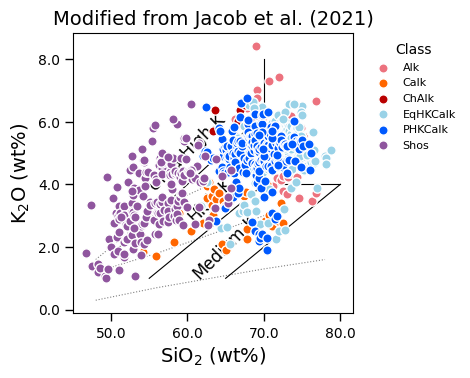

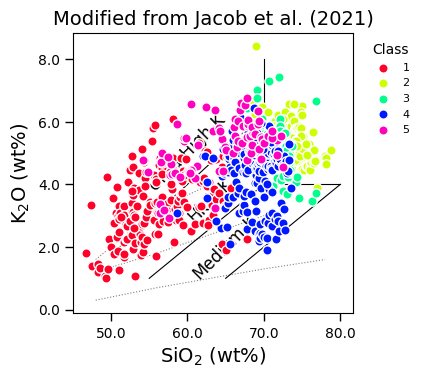

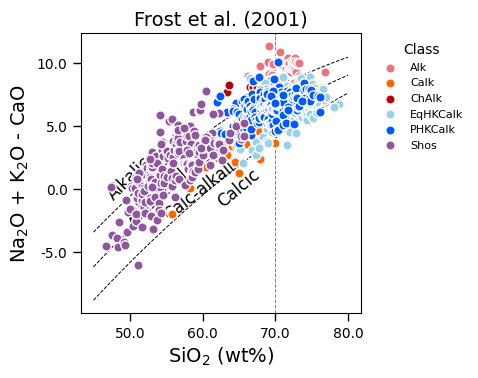

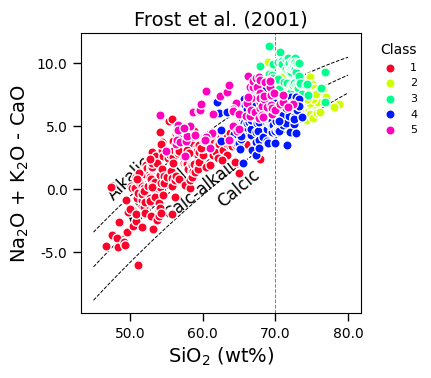

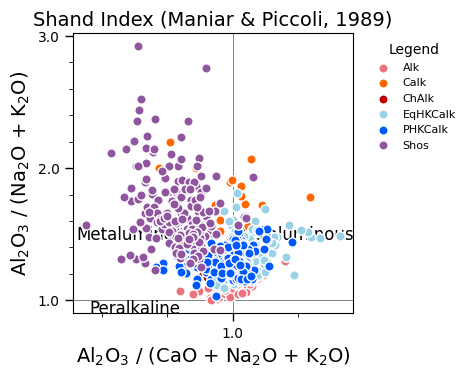

...

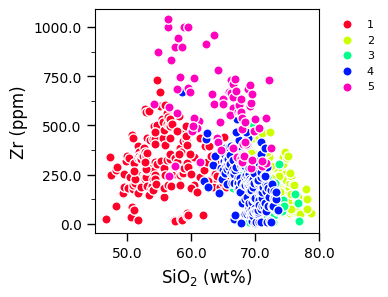

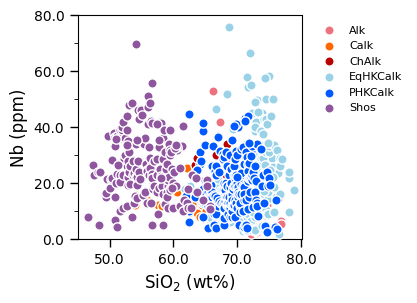

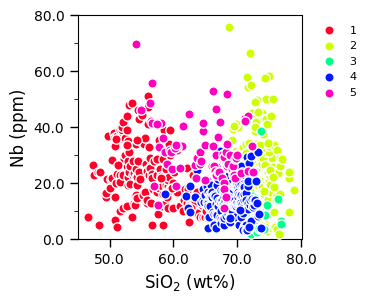

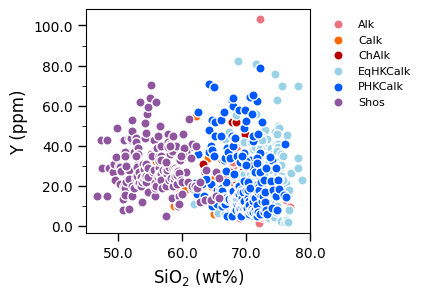

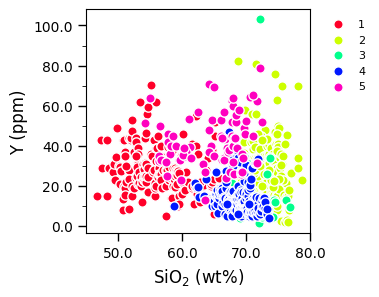

In [69]:
FIGURE_2_FUNCTIONS = {
    "2A": plot_k2o_vs_sio2,
    "2B": plot_alkalinity_index,
    "2C": plot_shand_index,
    "2D": plot_femgti_vs_mgfe,
    "2E": plot_femgti_vs_knk,
}

GROUPINGS = {
    "bySuite":   ("Label", suite_palette),
    "byCluster": (cluster_col, cluster_palette),
}

for fig_id, func in FIGURE_2_FUNCTIONS.items():
    for grouping_name, (group_col, palette) in GROUPINGS.items():
        func(
            df_som_results, group_col, palette,
            PATHS["figures_dir"] / f"Figure{fig_id}_{grouping_name}.pdf",
        )

for element, specs in TRACE_PLOT_SPECS.items():
    for grouping_name, (group_col, palette) in GROUPINGS.items():
        plot_trace_vs_sio2(
            df_som_results, element, group_col, palette,
            save_path=PATHS["figures_dir"] / f"Figure3_{element}_{grouping_name}.pdf",
            **specs,
        )